In [1]:
!pip install -q -U ultralytics

import ultralytics
from ultralytics import YOLO
import torch

print("ĐÃ CÀI ĐẶT THÀNH CÔNG ULTRALYTICS")
print("Phiên bản:", ultralytics.__version__)
print("GPU Available:", torch.cuda.is_available())


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ĐÃ CÀI ĐẶT THÀNH CÔNG ULTRALYTICS
Phiên bản: 8.4.178
GPU Available: True


In [2]:
from collections import Counter
from pathlib import Path

# Quét tất cả file txt gốc trước khi bị xử lý
raw_txt_files = list(Path("/kaggle/working/temp_raw").rglob("*.txt"))
if not raw_txt_files:
    raw_txt_files = list(Path("/kaggle/input").rglob("*.txt"))

raw_counter = Counter()
for f in raw_txt_files:
    for line in f.read_text().splitlines():
        if line.strip():
            raw_counter[int(line.split()[0])] += 1

print(" CÁC CLASS ID GỐC THỰC SỰ ĐANG CÓ TRONG DATASET:")
for cls_id, count in sorted(raw_counter.items()):
    print(f"  - Class ID {cls_id}: {count:,} nhãn")


 CÁC CLASS ID GỐC THỰC SỰ ĐANG CÓ TRONG DATASET:
  - Class ID 0: 5,751 nhãn
  - Class ID 1: 16,114 nhãn
  - Class ID 2: 9,154 nhãn


In [3]:
import os
import shutil
import zipfile
from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input")
DEST = Path("/kaggle/working/dataset_3class")
TEMP_EXTRACT = Path("/kaggle/working/temp_raw")

if DEST.exists():
    shutil.rmtree(DEST)
if TEMP_EXTRACT.exists():
    shutil.rmtree(TEMP_EXTRACT)

# 1. Giải nén dataset
zip_files = list(KAGGLE_INPUT.rglob("*.zip"))
if zip_files:
    for z in zip_files:
        with zipfile.ZipFile(z, 'r') as zip_ref:
            zip_ref.extractall(TEMP_EXTRACT)
    SEARCH_ROOT = TEMP_EXTRACT
else:
    SEARCH_ROOT = KAGGLE_INPUT

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}
all_label_files = list(SEARCH_ROOT.rglob("*.txt"))
image_map = {p.stem: p for p in SEARCH_ROOT.rglob("*") if p.is_file() and p.suffix in IMAGE_EXTS}

# 2. Xử lý giữ nguyên 3 class chuẩn: 0 (pothole), 1 (linear_crack), 2 (alligator_crack)
split_stats = {}

for split in ["train", "val", "test"]:
    dst_images = DEST / split / "images"
    dst_labels = DEST / split / "labels"
    dst_images.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    split_labels = [f for f in all_label_files if split in f.parts or (split == "val" and "valid" in f.parts)]
    if not split_labels and split == "train":
        split_labels = all_label_files

    kept, boxes = 0, 0
    for lbl in split_labels:
        new_lines = []
        for line in lbl.read_text().splitlines():
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            cls_id = int(parts[0])
            if cls_id in [0, 1, 2]:
                new_lines.append(line.strip())

        if not new_lines:
            continue

        src_img = image_map.get(lbl.stem)
        if src_img is None:
            continue

        (dst_labels / lbl.name).write_text("\n".join(new_lines) + "\n")
        dst_img = dst_images / src_img.name
        if not dst_img.exists():
            try:
                os.symlink(src_img, dst_img)
            except OSError:
                shutil.copy2(src_img, dst_img)
        kept += 1
        boxes += len(new_lines)

    split_stats[split] = (kept, boxes)

# In tổng quan dataset gọn gàng, chuyên nghiệp
total_damaged = sum(k for k, b in split_stats.values())
total_boxes = sum(b for k, b in split_stats.values())
clean_imgs = len(image_map) - total_damaged

print(f"[Dataset Info] Tổng: {len(image_map):,d} ảnh ({total_damaged:,d} ảnh hư hại + {clean_imgs:,d} ảnh sạch) | {total_boxes:,d} boxes")
for s in ["train", "val", "test"]:
    k, b = split_stats[s]
    tag = "TRAIN" if s == "train" else f"{s.upper()}  "
    print(f"-> {tag:<7}: {k:>6,d} ảnh ({b:>6,d} boxes)")

# 3. Ghi file data.yaml
yaml_text = f"""path: {DEST.resolve()}
train: train/images
val: val/images
test: test/images

names:
  0: pothole
  1: linear_crack
  2: alligator_crack
"""
(DEST / "data.yaml").write_text(yaml_text)
print("[Done] Cấu hình 3 lớp chuẩn: {0: 'pothole', 1: 'linear_crack', 2: 'alligator_crack'}")


[Dataset Info] Tổng: 22,590 ảnh (14,976 ảnh hư hại + 7,614 ảnh sạch) | 31,019 boxes
-> TRAIN  : 10,579 ảnh (21,860 boxes)
-> VAL    :  2,201 ảnh ( 4,611 boxes)
-> TEST   :  2,196 ảnh ( 4,548 boxes)
[Done] Cấu hình 3 lớp chuẩn: {0: 'pothole', 1: 'linear_crack', 2: 'alligator_crack'}


In [4]:
from collections import Counter
from pathlib import Path

DATASET = Path("/kaggle/working/dataset_3class")
class_names = {0: 'pothole', 1: 'linear_crack', 2: 'alligator_crack'}

for split in ["train", "val", "test"]:
    lbl_dir = DATASET / split / "labels"
    if not lbl_dir.exists():
        continue
    counter = Counter()
    for f in lbl_dir.glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                cls_id = int(line.split()[0])
                counter[cls_id] += 1

    print(f"\n[{split.upper()}]:")
    for cls_id in [0, 1, 2]:
        print(f"  Class {cls_id} ({class_names[cls_id]}): {counter.get(cls_id, 0):,} boxes")



[TRAIN]:
  Class 0 (pothole): 4,094 boxes
  Class 1 (linear_crack): 11,272 boxes
  Class 2 (alligator_crack): 6,494 boxes

[VAL]:
  Class 0 (pothole): 835 boxes
  Class 1 (linear_crack): 2,444 boxes
  Class 2 (alligator_crack): 1,332 boxes

[TEST]:
  Class 0 (pothole): 822 boxes
  Class 1 (linear_crack): 2,398 boxes
  Class 2 (alligator_crack): 1,328 boxes


In [5]:
from ultralytics import YOLO
import torch

# 1. Khởi tạo mô hình YOLO26n
model = YOLO("yolo26n.pt")

# Tự động nhận diện 2 GPU T4 hoặc 1 GPU trên Kaggle
devices = [i for i in range(torch.cuda.device_count())] if torch.cuda.is_available() else 'cpu'

# 2. Bắt đầu huấn luyện
results = model.train(
    data="/kaggle/working/dataset_3class/data.yaml",
    
    epochs=100,
    patience=15,             

    # Cấu hình ảnh & Batch size
    imgsz=640,
    batch=64 if len(devices) > 1 else 16,
    
    # Thiết lập lưu checkpoint từng epoch
    project="/kaggle/working/civiceye_training",
    name="yolo26n_rdd2022",
    save=True,
    save_period=1,           # Lưu đè last.pt sau MỖI epoch
    
    # Tối ưu phần cứng & hội tụ
    device=devices,
    workers=4,
    optimizer='AdamW',
    lr0=0.001,
    pretrained=True,
    val=True,
    seed=42,
    verbose=True
)


Ultralytics 8.4.178 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_3class/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      2/100      6.01G      1.922      2.913    0.01836         25        640: 100% ━━━━━━━━━━━━ 166/166 2.1it/s 1:180.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.5it/s 11.7s0.6s
                   all       2201       4611      0.342      0.248      0.184     0.0661

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/100      6.01G      1.934      2.731    0.01837         34        640: 100% ━━━━━━━━━━━━ 166/166 2.1it/s 1:170.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 1.7it/s 10.9s0.5s
                   all       2201       4611      0.237      0.248       0.16     0.0578

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/100      6.01G       1.92      2.608    0.01808         34       

In [6]:
from ultralytics import YOLO
from pathlib import Path

BEST_MODEL = Path("/kaggle/working/civiceye_training/yolo26n_rdd2022/weights/best.pt")

if BEST_MODEL.exists():
    best_model = YOLO(str(BEST_MODEL))
    
    print("--- KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ---")
    metrics = best_model.val(data="/kaggle/working/dataset_3class/data.yaml", split="val", imgsz=640)
    
    print("\n" + "="*45)
    print(f" mAP@50:     {metrics.box.map50:.4f}")
    print(f" mAP@50-95:  {metrics.box.map:.4f}")
    
    t_inf = metrics.speed.get("inference", 0)
    print(f"Inference:     {t_inf:.2f} ms")
    print(f"FPS:           {1000/t_inf:.1f} FPS")
   
    print("="*45)
    
    print("\nChi tiết mAP@50-95 từng lớp:")
    for name, score in zip(metrics.names.values(), metrics.box.maps):
        print(f" - {name:20s}: {score:.4f}")


--- KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION ---
Ultralytics 8.4.178 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 70.6±42.8 MB/s, size: 53.7 KB)
val: Scanning /kaggle/working/dataset_3class/val/labels.cache... 2201 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2201/2201 769.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 7.1it/s 19.6s0.1s
                   all       2201       4611      0.686      0.586      0.643      0.324
               pothole        452        835      0.672      0.485      0.554      0.241
          linear_crack       1311       2444      0.684      0.616      0.673      0.362
       alligator_crack       1048       1332      0.703      0.658      0.702      0.368
Speed: 1.0ms preprocess, 3.8ms inference, 0.0ms loss, 1.1ms postproce

In [7]:
import shutil
from pathlib import Path

SOURCE_BEST = Path("/kaggle/working/civiceye_training/yolo26n_rdd2022/weights/best.pt")
FINAL_MODEL = Path("/kaggle/working/yolo26n_rdd_3class_best.pt")

if SOURCE_BEST.exists():
    shutil.copy2(SOURCE_BEST, FINAL_MODEL)
    print(f" Đã lưu model hoàn tất: {FINAL_MODEL}")
    print(f" Dung lượng: {round(FINAL_MODEL.stat().st_size / 1024**2, 2)} MB")


 Đã lưu model hoàn tất: /kaggle/working/yolo26n_rdd_3class_best.pt
 Dung lượng: 5.21 MB


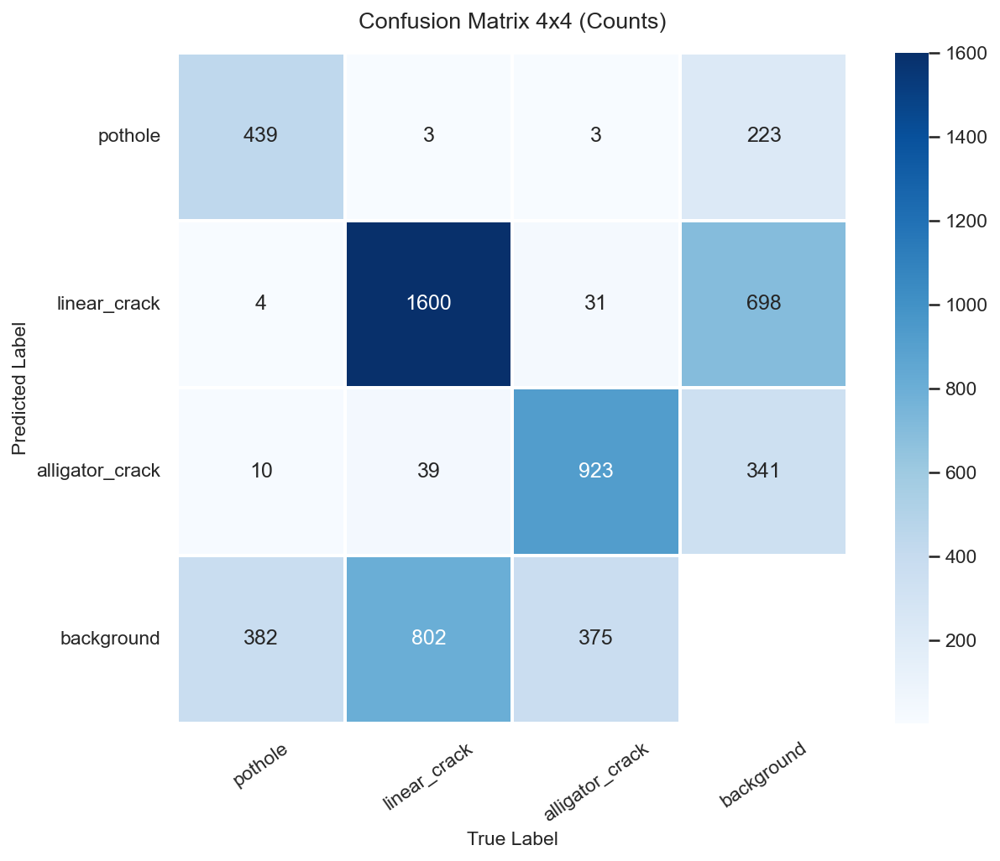

/kaggle/working/confusion_matrix_4x4_counts.png

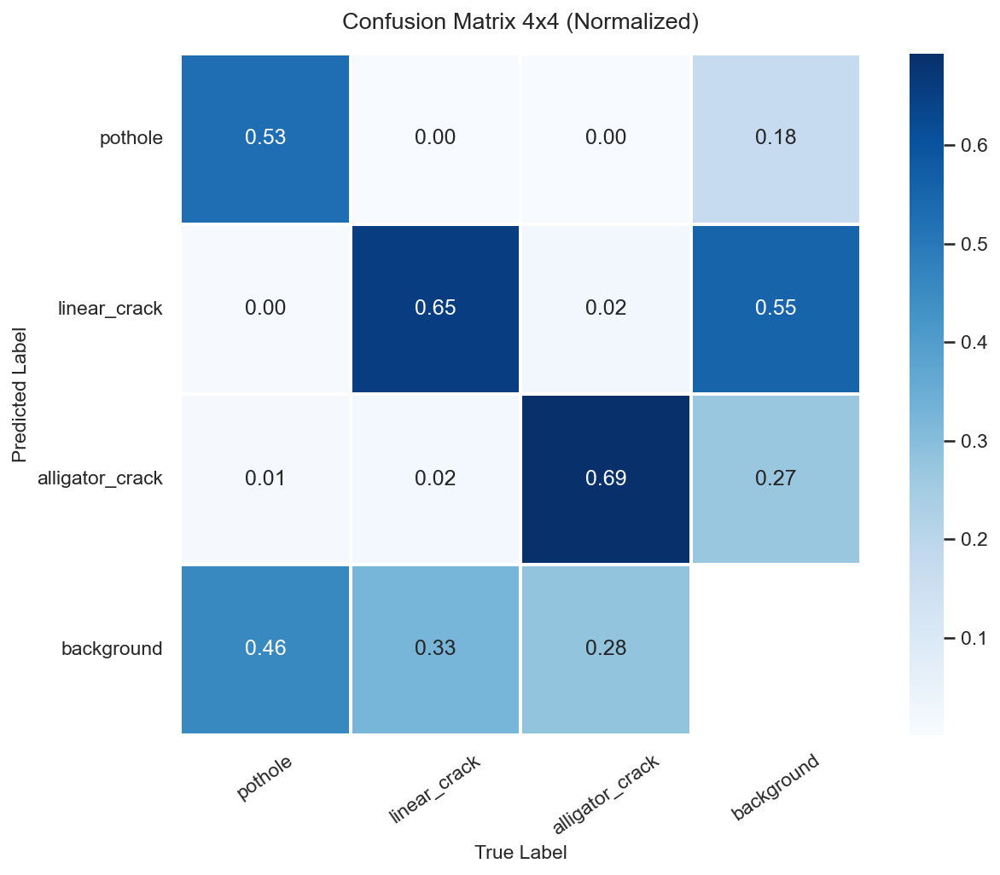

/kaggle/working/confusion_matrix_4x4_normalized.png

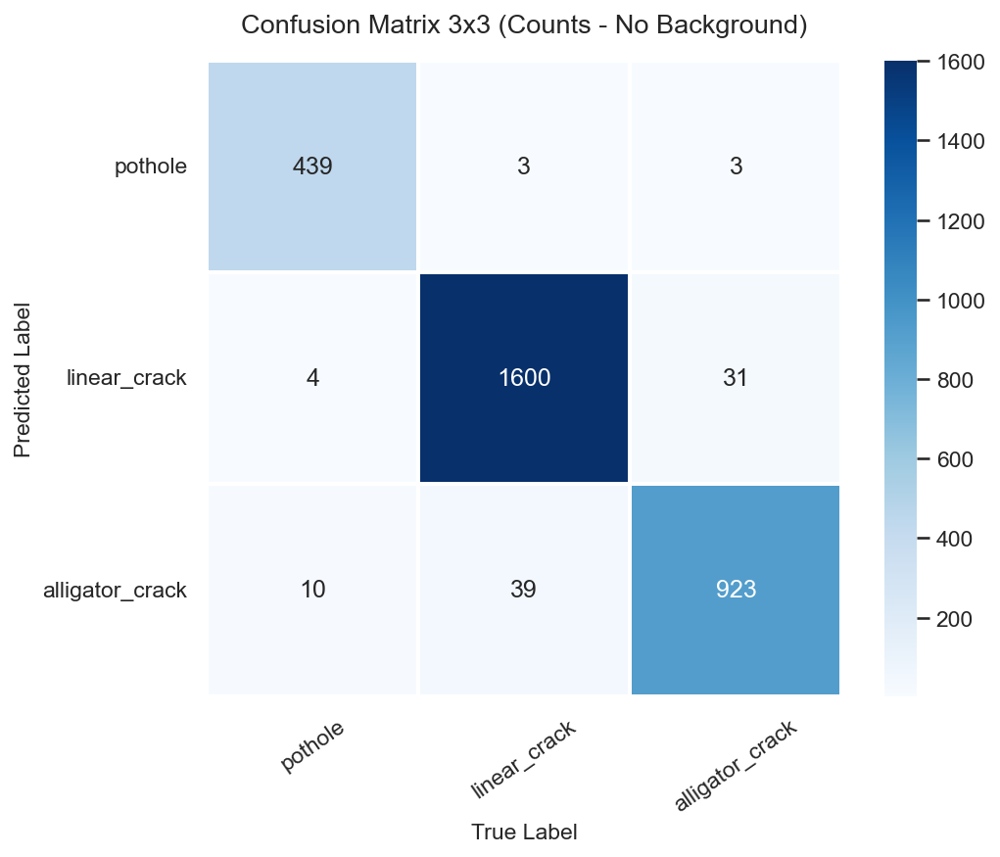

/kaggle/working/confusion_matrix_3x3_counts.png

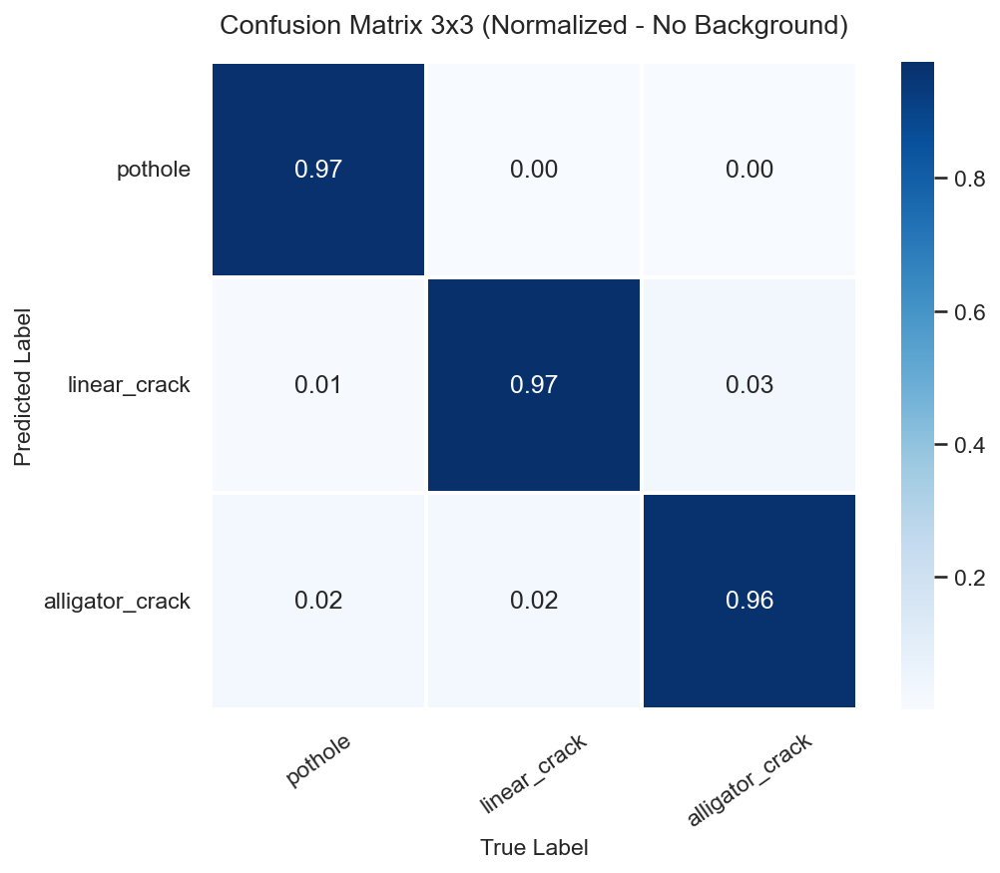

/kaggle/working/confusion_matrix_3x3_normalized.png

In [34]:
import io
import logging
import os
from pathlib import Path
import sys
from IPython.display import FileLink, display
from contextlib import redirect_stderr, redirect_stdout
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from ultralytics import YOLO
from ultralytics.utils import LOGGER

# ============================================================
# 1. CAU HINH
# ============================================================
MODEL_PATH = (
    "/kaggle/working/civiceye_training/yolo26n_rdd2022/weights/best.pt"
)

DATA_YAML_PATH = "/kaggle/working/dataset_3class/data.yaml"

OUTPUT_DIR = Path("/kaggle/working")

CLASS_NAMES = ["pothole", "linear_crack", "alligator_crack"]

FULL_LABELS = CLASS_NAMES + ["background"]
NC = len(CLASS_NAMES)

# ============================================================
# 2. VALIDATION 
# ============================================================
old_level = LOGGER.level
old_disabled = LOGGER.disabled
old_propagate = LOGGER.propagate

try:
  LOGGER.setLevel(logging.CRITICAL + 1)
  LOGGER.disabled = True
  LOGGER.propagate = False

  with redirect_stdout(io.StringIO()), redirect_stderr(io.StringIO()):
    model = YOLO(MODEL_PATH)

    metrics = model.val(
        data=DATA_YAML_PATH,
        imgsz=640,
        plots=True,
        conf=0.25,
        iou=0.45,
        project=str(OUTPUT_DIR / "temp_val"),
        name="val",
        exist_ok=True,
        verbose=False,
    )

finally:
  LOGGER.setLevel(old_level)
  LOGGER.disabled = old_disabled
  LOGGER.propagate = old_propagate

raw_matrix = metrics.confusion_matrix.matrix.copy().astype(float)

if raw_matrix.shape != (NC + 1, NC + 1):
  raise ValueError(
      f"Expected a 4x4 matrix, got {raw_matrix.shape}. "
      "Check the dataset class configuration."
  )

# ============================================================
# 3. TAO 4 MA TRAN
# ============================================================

# A. 4x4 COUNTS
cm_4x4_counts = raw_matrix.copy()
cm_4x4_counts[NC, NC] = np.nan

# B. 4x4 NORMALIZED - CHUAN HOA THEO COT
col_sums_4x4 = raw_matrix.sum(axis=0, keepdims=True)

cm_4x4_norm = np.divide(
    raw_matrix, col_sums_4x4, out=np.zeros_like(raw_matrix), where=(col_sums_4x4 != 0)
)
cm_4x4_norm[NC, NC] = np.nan

# C. 3x3 COUNTS - BO BACKGROUND
cm_3x3_counts = raw_matrix[:NC, :NC].copy()

# D. 3x3 NORMALIZED - CHUAN HOA THEO COT
col_sums_3x3 = cm_3x3_counts.sum(axis=0, keepdims=True)

cm_3x3_norm = np.divide(
    cm_3x3_counts,
    col_sums_3x3,
    out=np.zeros_like(cm_3x3_counts),
    where=(col_sums_3x3 != 0),
)

# ============================================================
# 4. VE, LUU VA XUAT LINK TAI CHUAN
# ============================================================
sns.set_theme(style="white", font_scale=1.0)

matrix_tasks = [
    (
        cm_4x4_counts,
        FULL_LABELS,
        ".0f",
        "Confusion Matrix 4x4 (Counts)",
        "confusion_matrix_4x4_counts.png",
    ),
    (
        cm_4x4_norm,
        FULL_LABELS,
        ".2f",
        "Confusion Matrix 4x4 (Normalized)",
        "confusion_matrix_4x4_normalized.png",
    ),
    (
        cm_3x3_counts,
        CLASS_NAMES,
        ".0f",
        "Confusion Matrix 3x3 (Counts - No Background)",
        "confusion_matrix_3x3_counts.png",
    ),
    (
        cm_3x3_norm,
        CLASS_NAMES,
        ".2f",
        "Confusion Matrix 3x3 (Normalized - No Background)",
        "confusion_matrix_3x3_normalized.png",
    ),
]

for cm, labels, fmt, title, filename in matrix_tasks:
  save_path = OUTPUT_DIR / filename

  fig_size = (9, 7) if len(labels) == 4 else (7.5, 6)
  fig, ax = plt.subplots(figsize=fig_size, dpi=150)

  sns.heatmap(
      cm,
      annot=True,
      fmt=fmt,
      cmap="Blues",
      xticklabels=labels,
      yticklabels=labels,
      cbar=True,
      square=True,
      linewidths=1,
      linecolor="white",
      ax=ax,
  )

  ax.set_title(title, fontsize=13, fontweight="bold", pad=14)
  ax.set_xlabel("True Label", fontsize=11, fontweight="bold")
  ax.set_ylabel("Predicted Label", fontsize=11, fontweight="bold")

  ax.tick_params(axis="x", labelrotation=35)
  ax.tick_params(axis="y", labelrotation=0)

  fig.tight_layout()
  fig.savefig(save_path, dpi=300, bbox_inches="tight")
  plt.show()
  plt.close(fig)

  
  display(FileLink(filename))


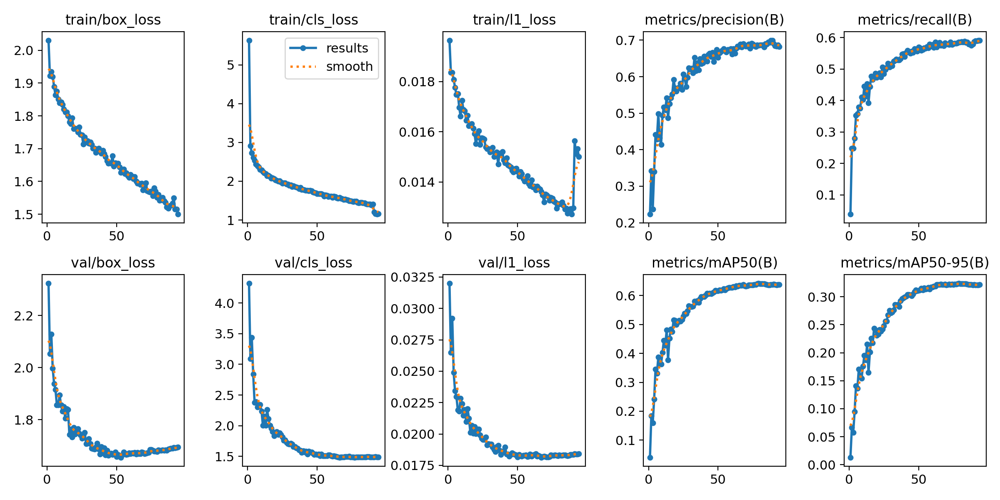

/kaggle/working/results.png

In [36]:
import shutil
from IPython.display import FileLink, display

# Hiển thị trực tiếp ảnh results.png có sẵn của YOLO
display(Image("/kaggle/working/civiceye_training/yolo26n_rdd2022/results.png"))
# Copy file ra ngoài thư mục làm việc và tạo link tải
shutil.copy(
    "/kaggle/working/civiceye_training/yolo26n_rdd2022/results.png",
    "/kaggle/working/results.png",
)
display(FileLink("results.png"))

 Đã nạp dữ liệu huấn luyện thành công (94 epochs).


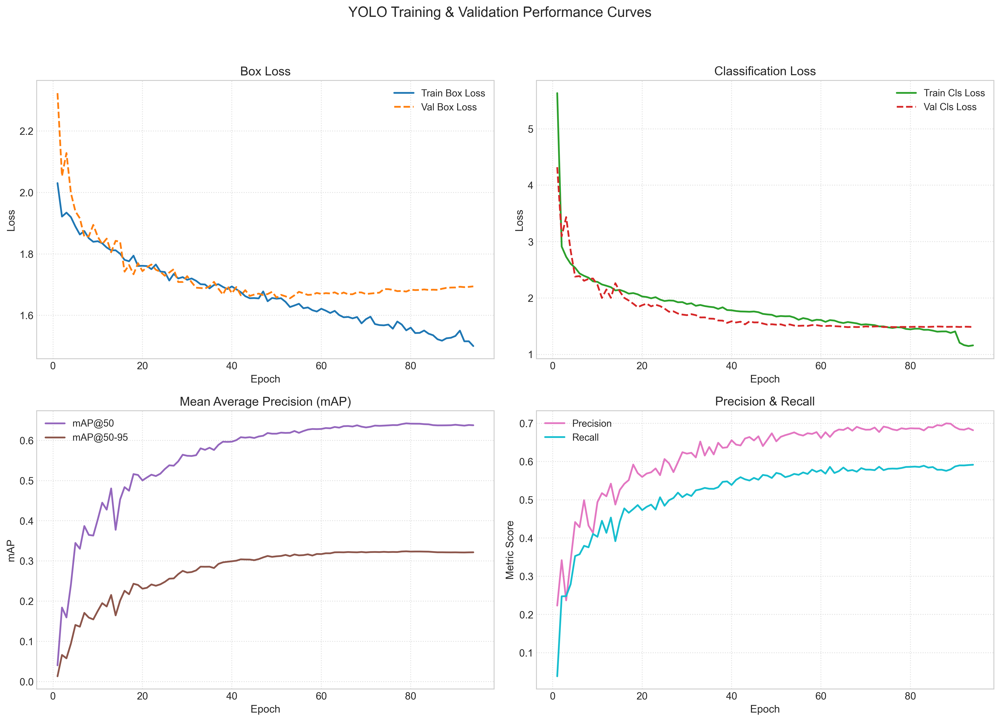


Đã lưu biểu đồ huấn luyện tại: /kaggle/working/training_curves.png
Link tải ảnh biểu đồ:


/kaggle/working/training_curves.png

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink

# =====================================================================
# 1. ĐIỀN ĐƯỜNG DẪN THƯ MỤC TRAIN HOẶC FILE results.csv CỦA BẠN
# =====================================================================
RESULTS_CSV_PATH = "/kaggle/working/civiceye_training/yolo26n_rdd2022/results.csv"

# Nơi lưu ảnh biểu đồ xuất ra
SAVE_PLOT_PATH   = "/kaggle/working/training_curves.png"

# =====================================================================
# 2. ĐỌC DỮ LIỆU TỪ results.csv
# =====================================================================
csv_file = Path(RESULTS_CSV_PATH)
if not csv_file.exists():
    # Tự động tìm kiếm nếu đường dẫn trên chưa đúng
    found = list(Path("/kaggle/working").rglob("results.csv"))
    if found:
        csv_file = found[0]
        print(f"🔍 Đã tự động tìm thấy file tại: {csv_file}")
    else:
        raise FileNotFoundError(f" Không tìm thấy file `{RESULTS_CSV_PATH}`! Hãy kiểm tra lại thư mục train.")

# Đọc dữ liệu và chuẩn hóa tên cột (xóa khoảng trắng thừa ở tên cột)
df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip()

print(f" Đã nạp dữ liệu huấn luyện thành công ({len(df)} epochs).")

# =====================================================================
# 3. VẼ BIỂU ĐỒ HUẤN LUYỆN (4 ĐỒ THỊ)
# =====================================================================
plt.figure(figsize=(16, 12), dpi=300)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

epochs = df['epoch']

# --- Đồ thị 1: Box Loss (Train vs Val) ---
plt.subplot(2, 2, 1)
plt.plot(epochs, df['train/box_loss'], label='Train Box Loss', color='#1f77b4', linewidth=2)
plt.plot(epochs, df['val/box_loss'], label='Val Box Loss', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title('Box Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# --- Đồ thị 2: Class Loss (Train vs Val) ---
plt.subplot(2, 2, 2)
plt.plot(epochs, df['train/cls_loss'], label='Train Cls Loss', color='#2ca02c', linewidth=2)
plt.plot(epochs, df['val/cls_loss'], label='Val Cls Loss', color='#d62728', linewidth=2, linestyle='--')
plt.title('Classification Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# --- Đồ thị 3: mAP@50 & mAP@50-95 ---
plt.subplot(2, 2, 3)
plt.plot(epochs, df['metrics/mAP50(B)'], label='mAP@50', color='#9467bd', linewidth=2)
plt.plot(epochs, df['metrics/mAP50-95(B)'], label='mAP@50-95', color='#8c564b', linewidth=2)
plt.title('Mean Average Precision (mAP)', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('mAP', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# --- Đồ thị 4: Precision & Recall ---
plt.subplot(2, 2, 4)
plt.plot(epochs, df['metrics/precision(B)'], label='Precision', color='#e377c2', linewidth=2)
plt.plot(epochs, df['metrics/recall(B)'], label='Recall', color='#17becf', linewidth=2)
plt.title('Precision & Recall', fontsize=14, fontweight='bold')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Metric Score', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('YOLO Training & Validation Performance Curves', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# =====================================================================
# 4. LƯU ẢNH VÀ HIỂN THỊ
# =====================================================================
plt.savefig(SAVE_PLOT_PATH, dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*50)
print(f"Đã lưu biểu đồ huấn luyện tại: {SAVE_PLOT_PATH}")
print("Link tải ảnh biểu đồ:")
display(FileLink(SAVE_PLOT_PATH.split('/')[-1]))
print("="*50)


📸 ẢNH 1/50: Japan_000762.jpg


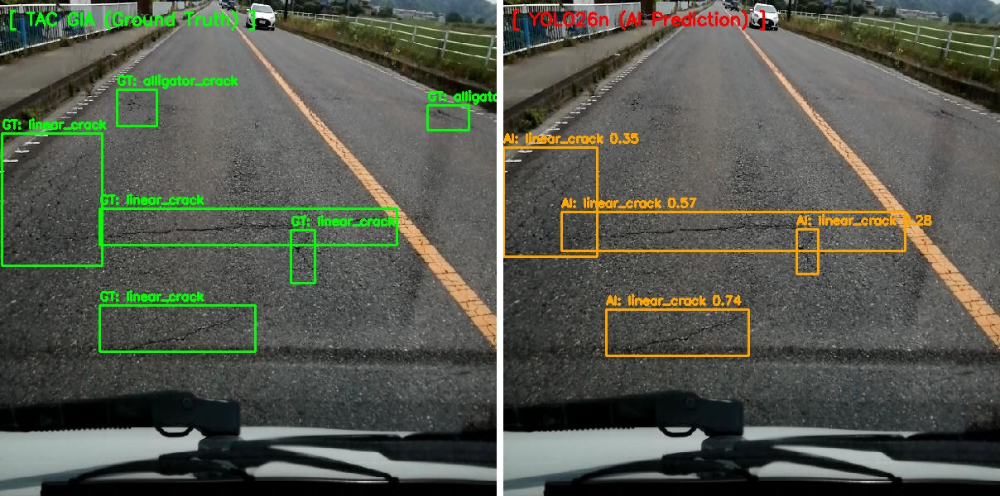

📸 ẢNH 2/50: Japan_005017.jpg


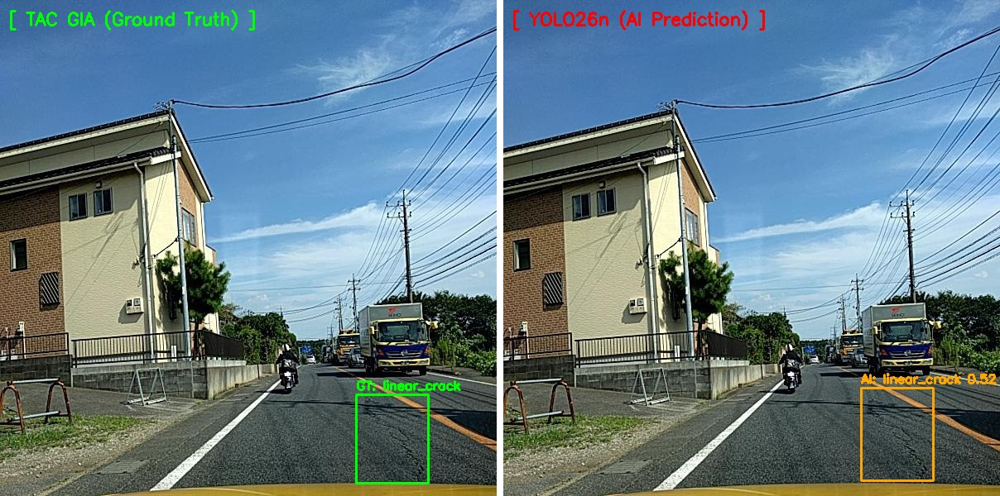

📸 ẢNH 3/50: Japan_013125.jpg


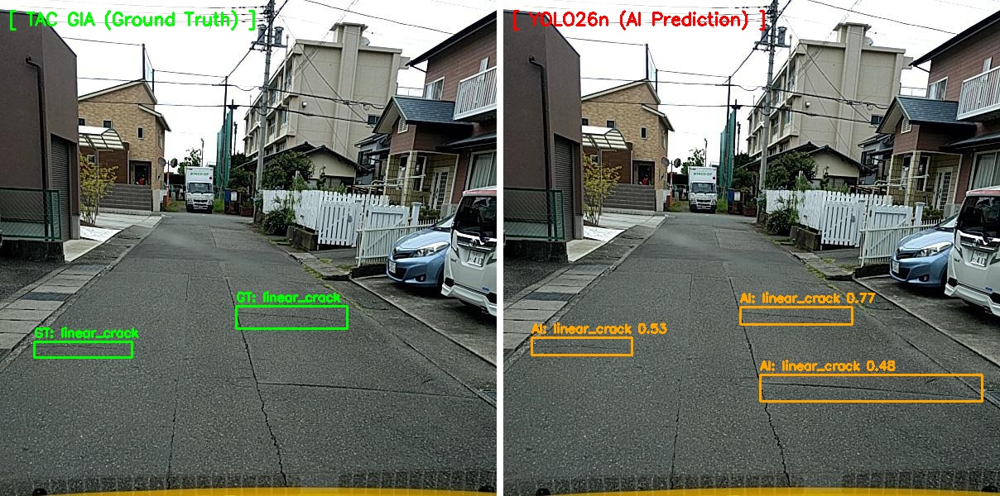

📸 ẢNH 4/50: Japan_005623.jpg


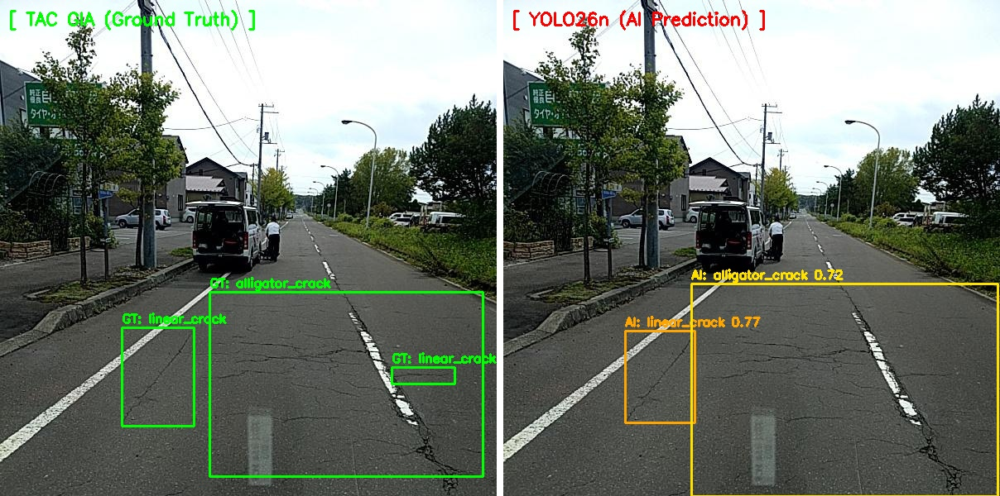

📸 ẢNH 5/50: India_006690.jpg


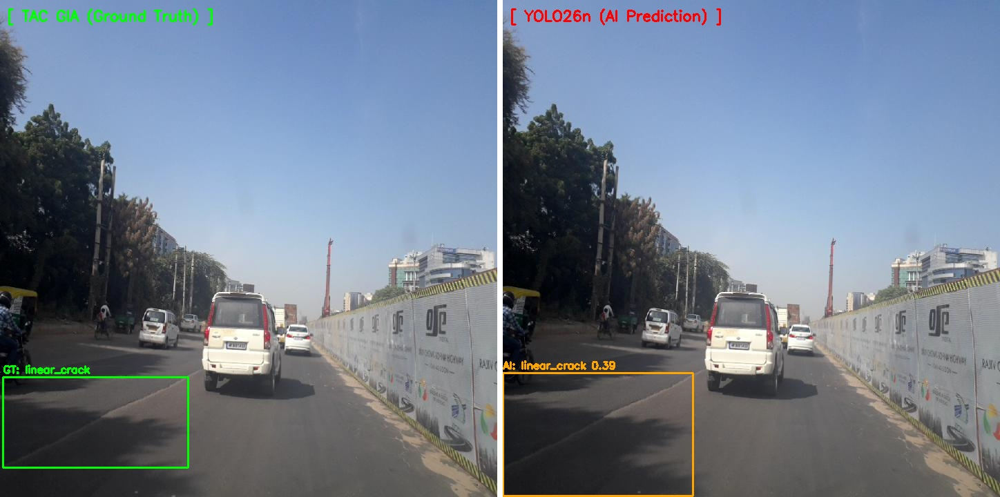

📸 ẢNH 6/50: Japan_010050.jpg


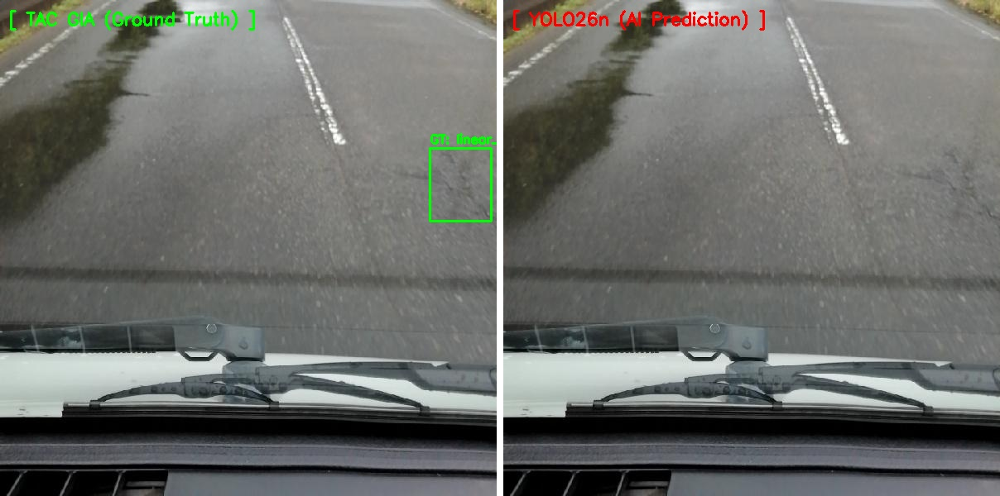

📸 ẢNH 7/50: China_MotorBike_001128.jpg


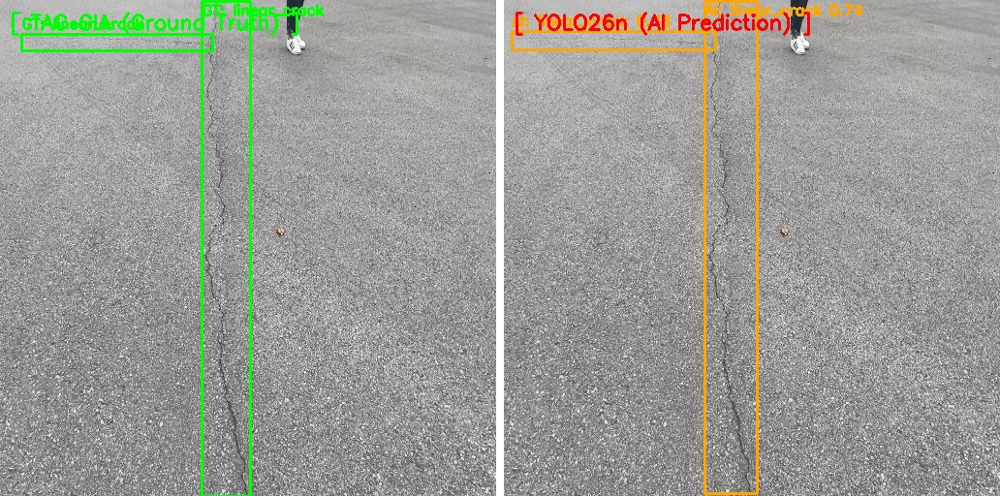

📸 ẢNH 8/50: Japan_011407.jpg


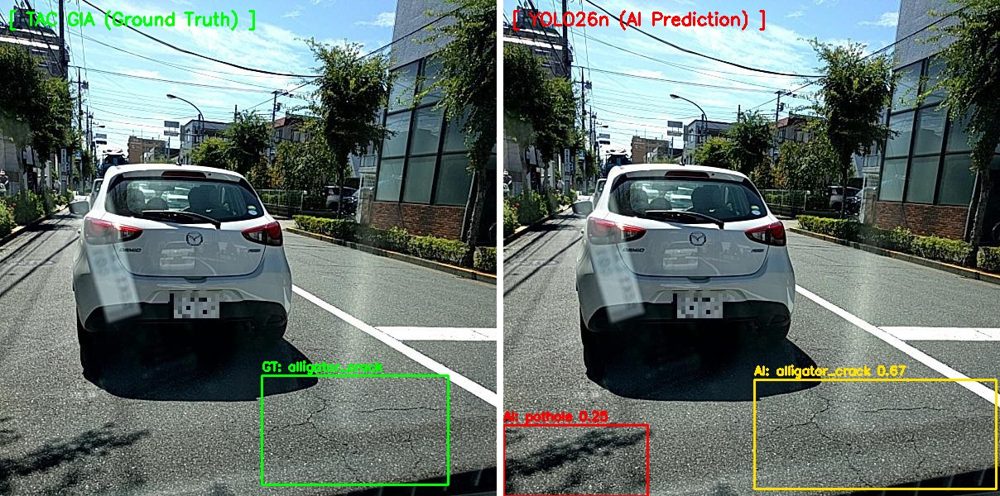

📸 ẢNH 9/50: India_006592.jpg


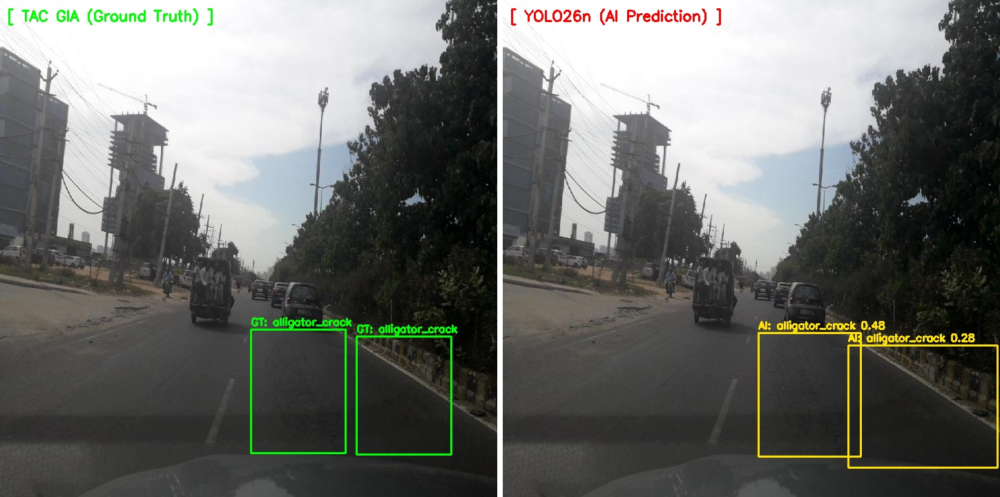

📸 ẢNH 10/50: Japan_005879.jpg


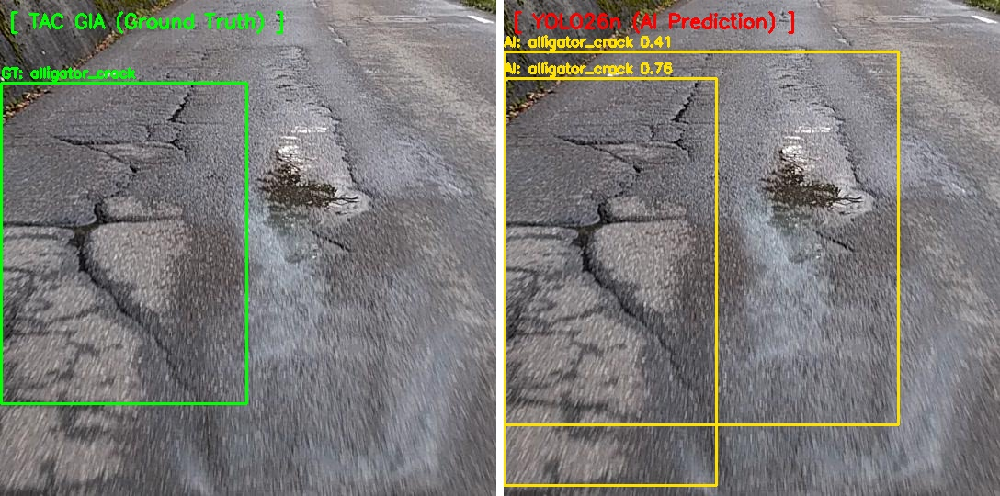

📸 ẢNH 11/50: China_MotorBike_001583.jpg


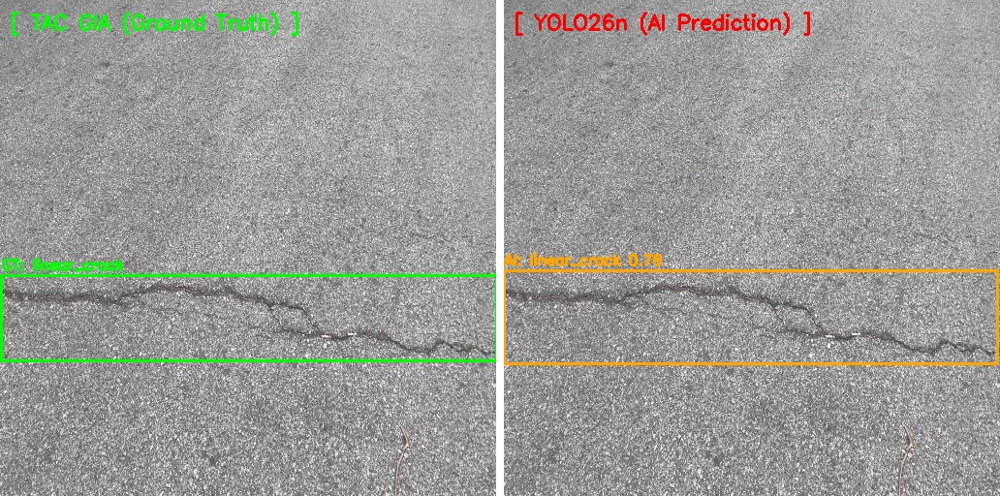

📸 ẢNH 12/50: Japan_001625.jpg


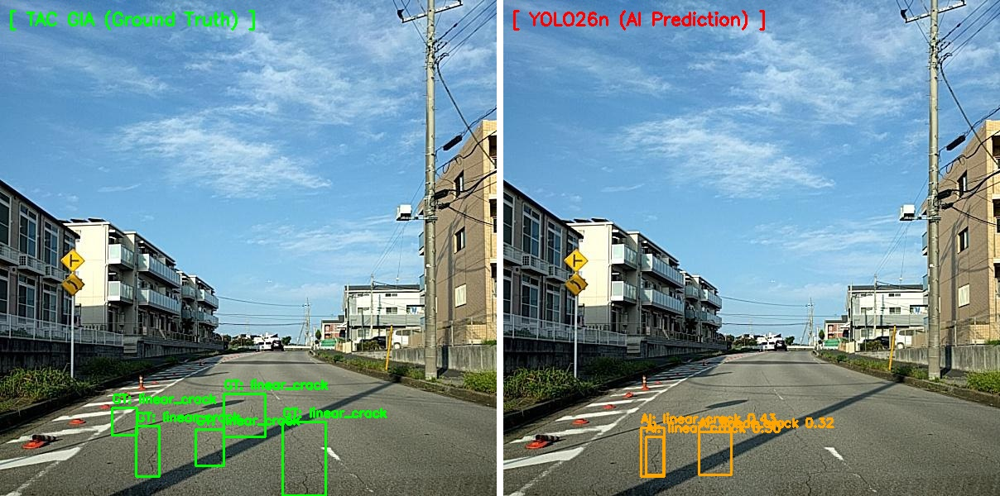

📸 ẢNH 13/50: India_001687.jpg


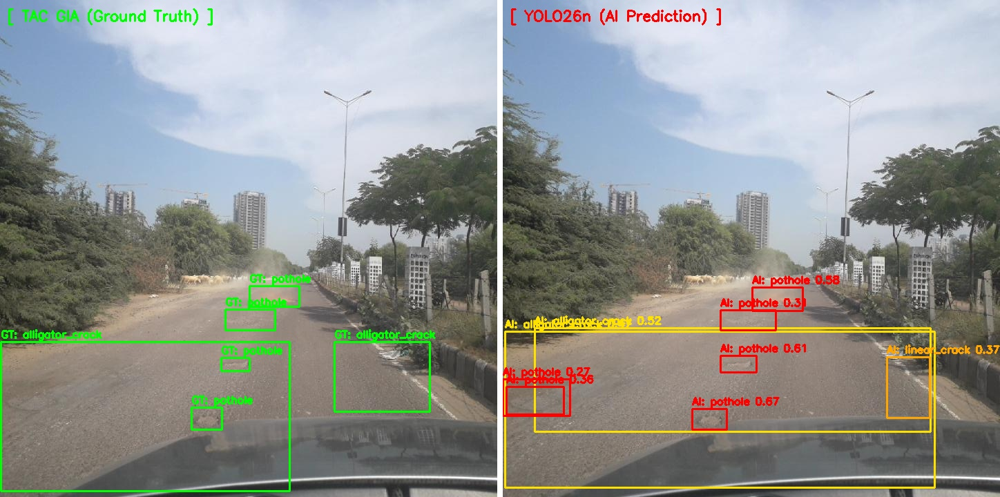

📸 ẢNH 14/50: Japan_012687.jpg


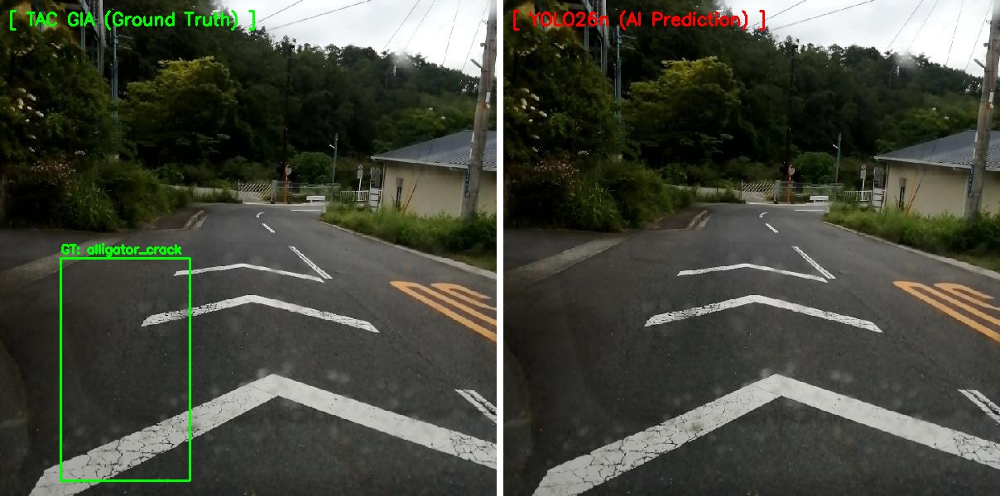

📸 ẢNH 15/50: India_004828.jpg


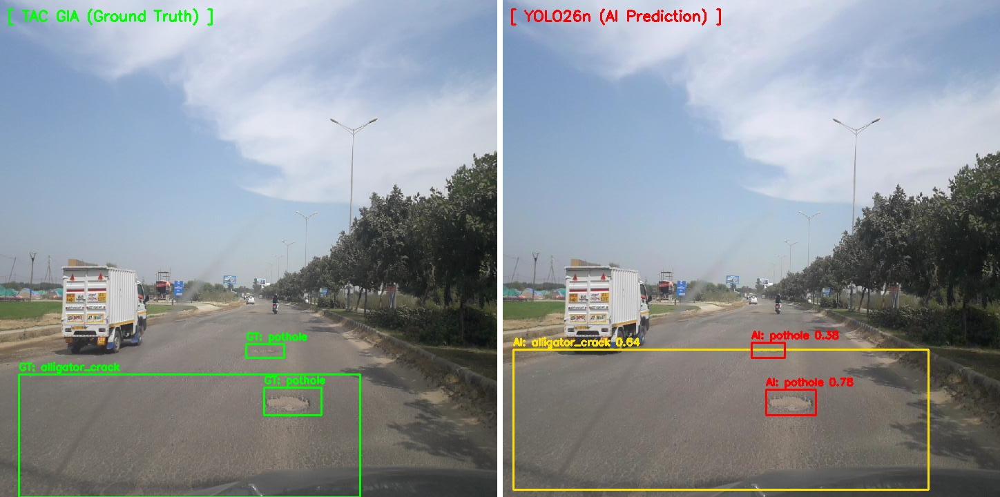

📸 ẢNH 16/50: India_004181.jpg


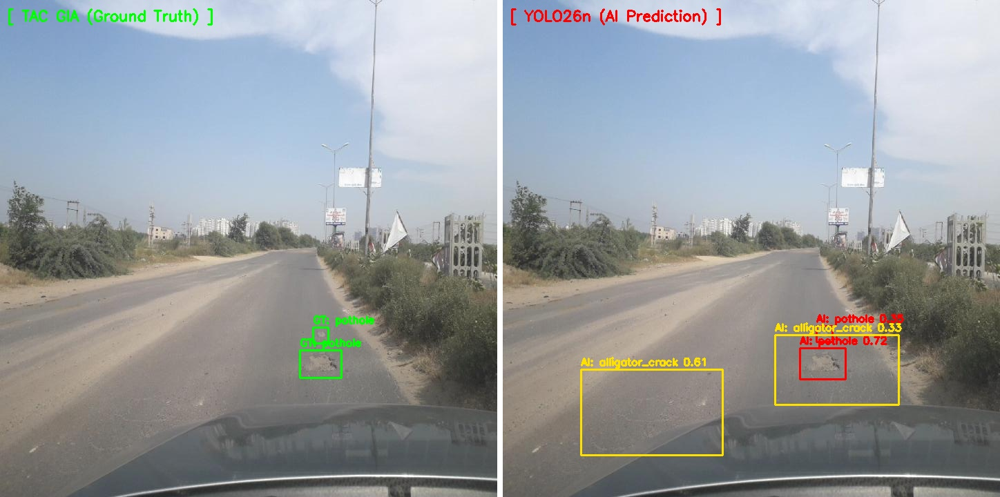

📸 ẢNH 17/50: Japan_001513.jpg


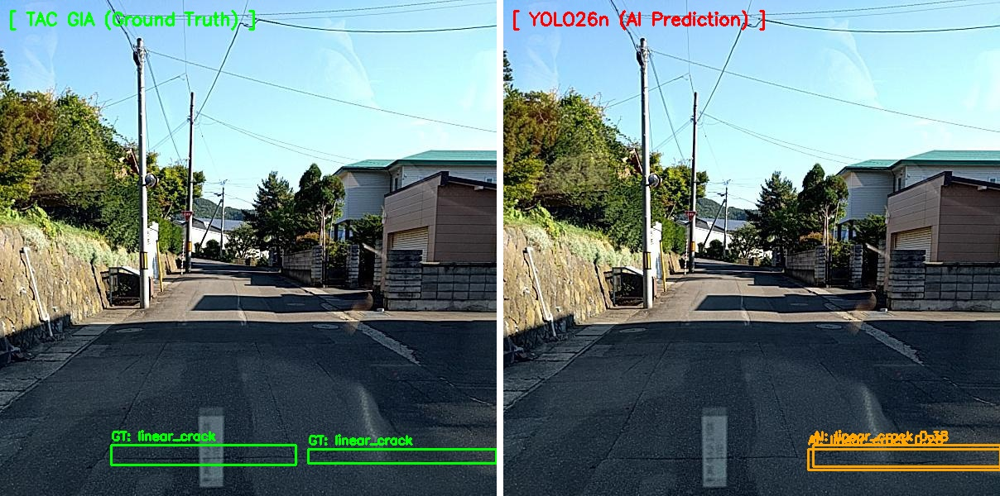

📸 ẢNH 18/50: Japan_005221.jpg


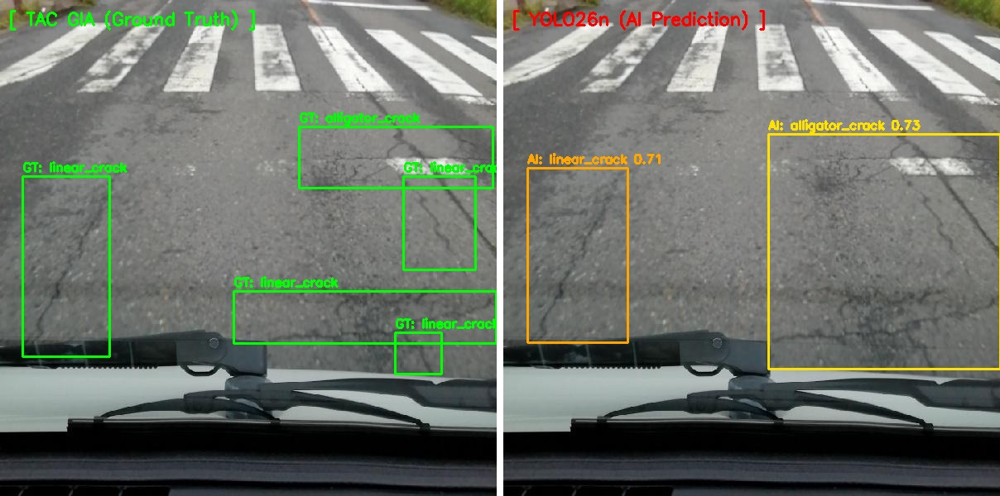

📸 ẢNH 19/50: Japan_010257.jpg


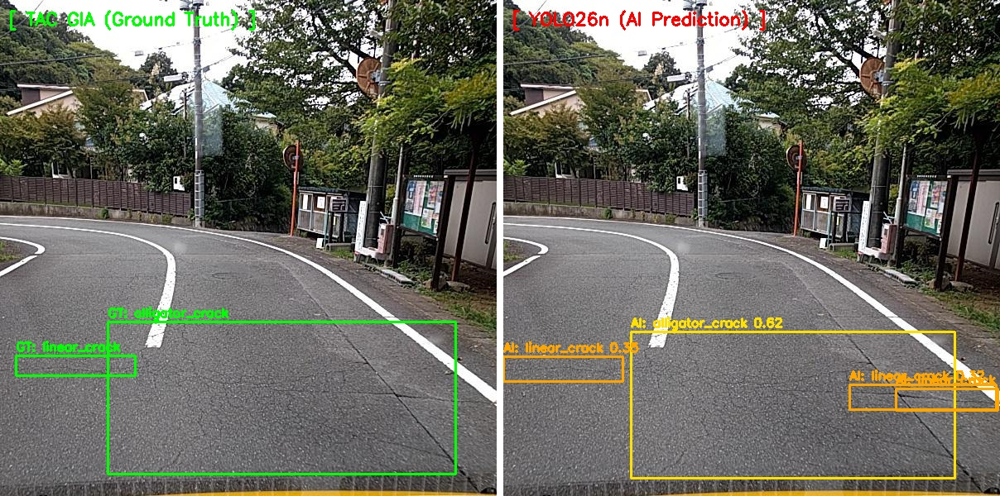

📸 ẢNH 20/50: China_MotorBike_001460.jpg


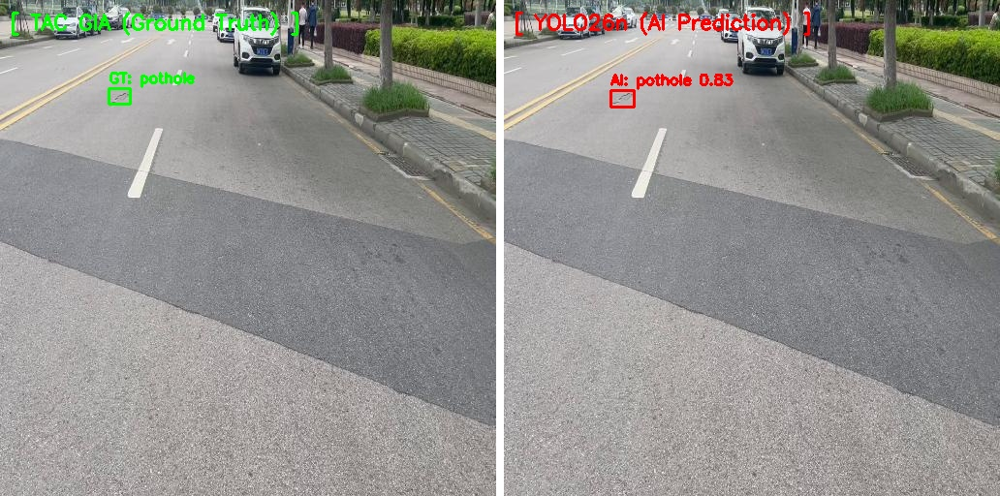

📸 ẢNH 21/50: Japan_004011.jpg


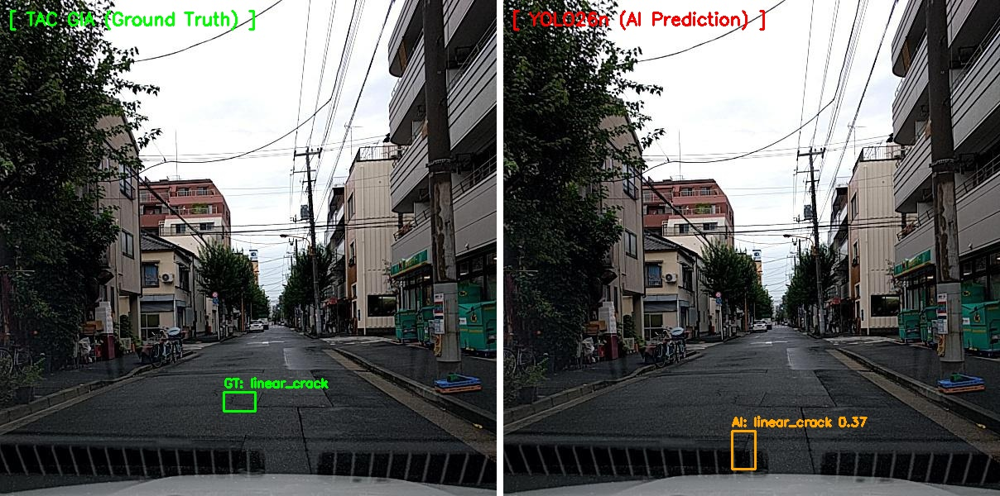

📸 ẢNH 22/50: Japan_002193.jpg


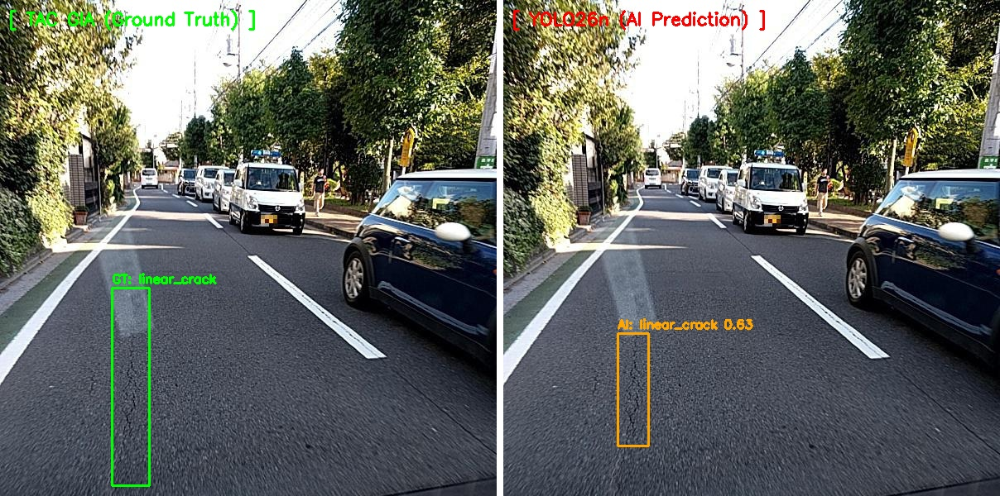

📸 ẢNH 23/50: Japan_005371.jpg


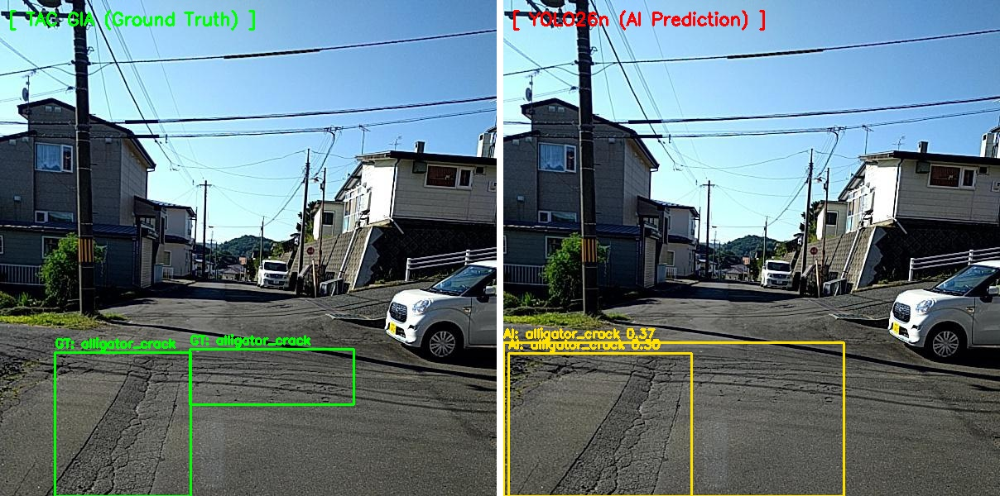

📸 ẢNH 24/50: India_005693.jpg


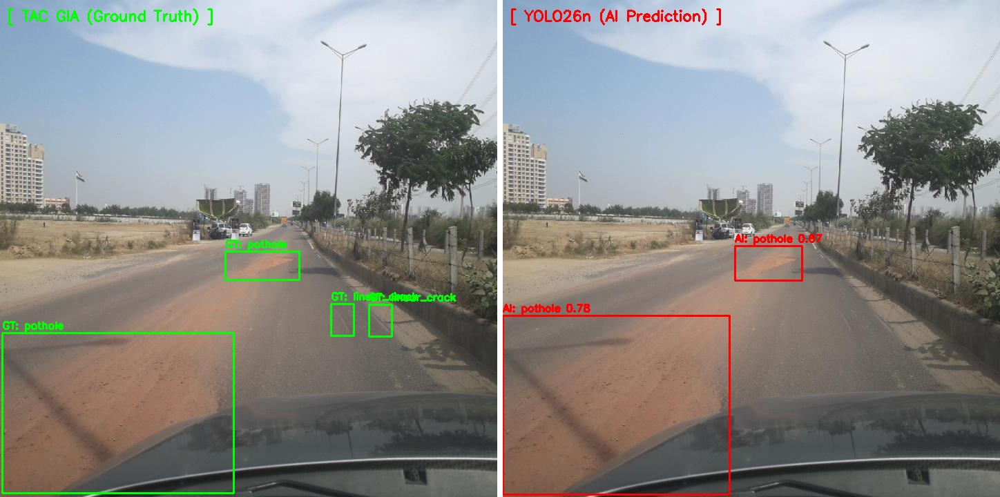

📸 ẢNH 25/50: China_Drone_002245.jpg


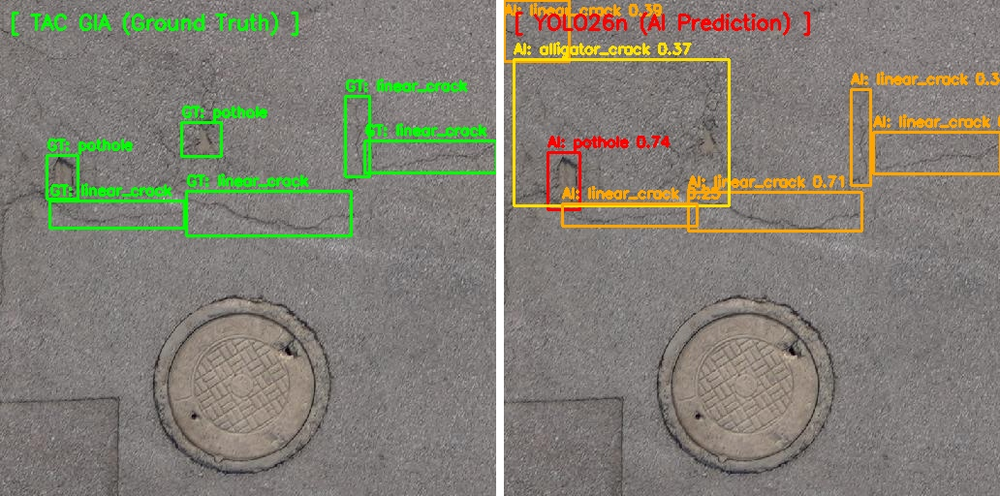

📸 ẢNH 26/50: India_000092.jpg


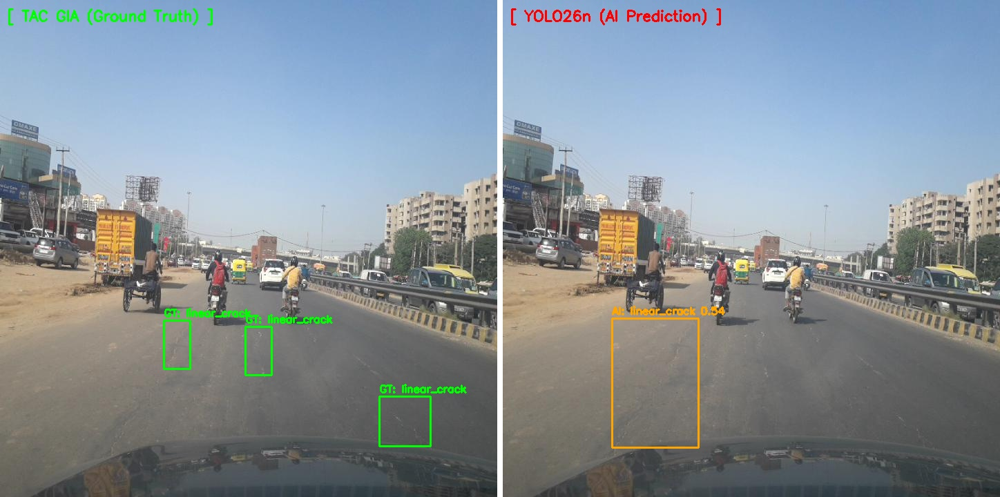

📸 ẢNH 27/50: India_003879.jpg


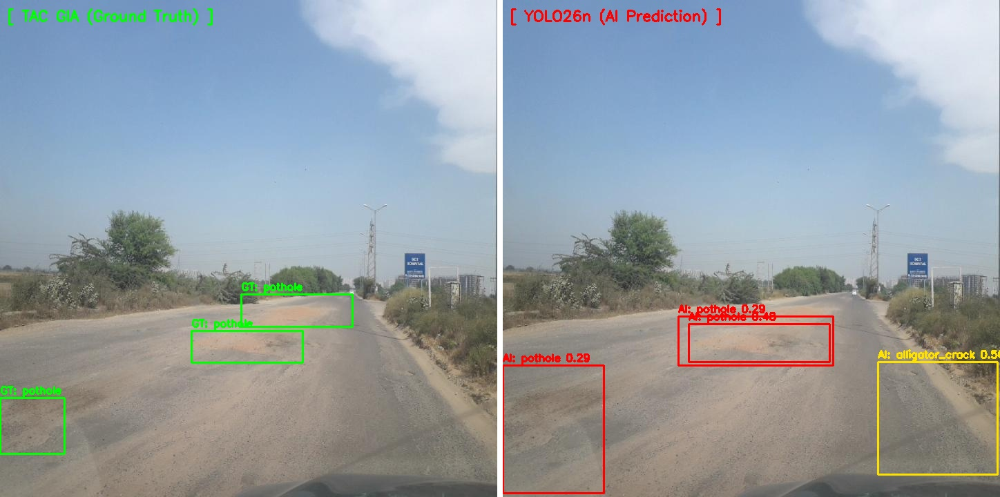

📸 ẢNH 28/50: China_MotorBike_000727.jpg


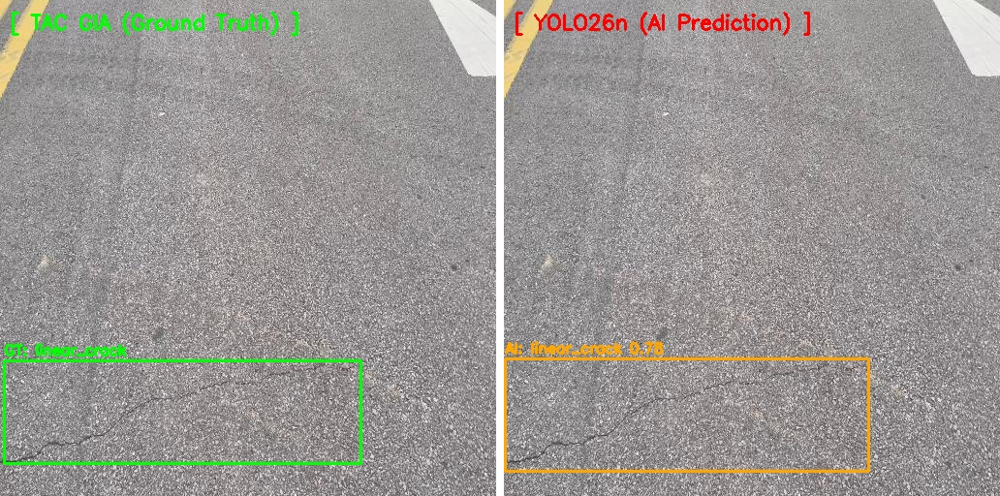

📸 ẢNH 29/50: Japan_011002.jpg


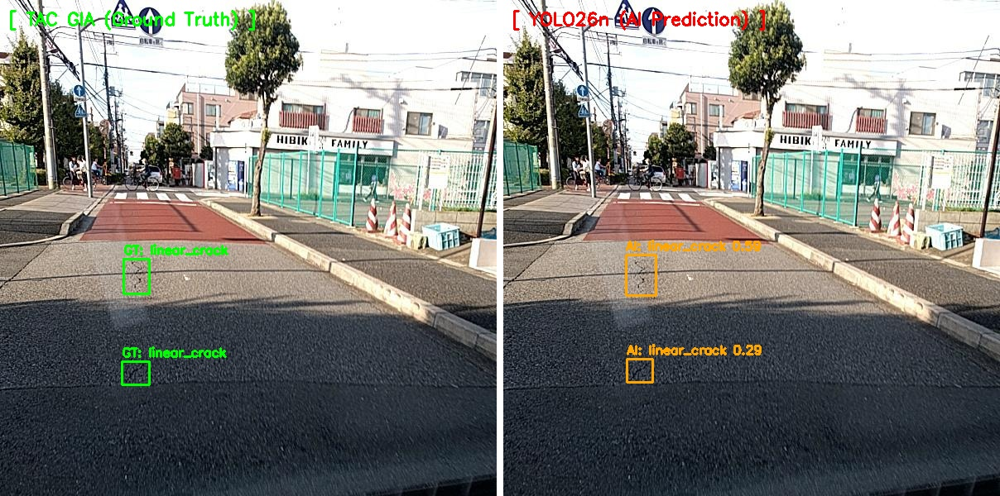

📸 ẢNH 30/50: China_MotorBike_001386.jpg


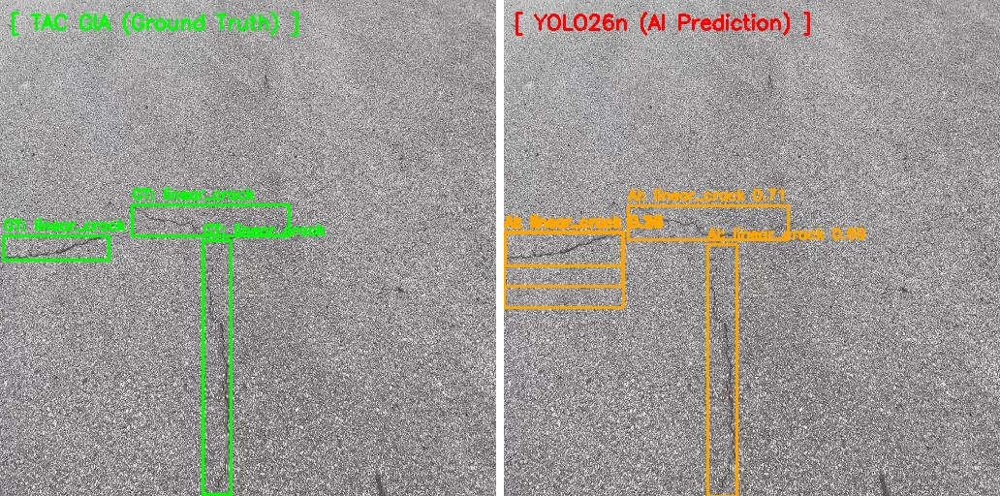

📸 ẢNH 31/50: Japan_002695.jpg


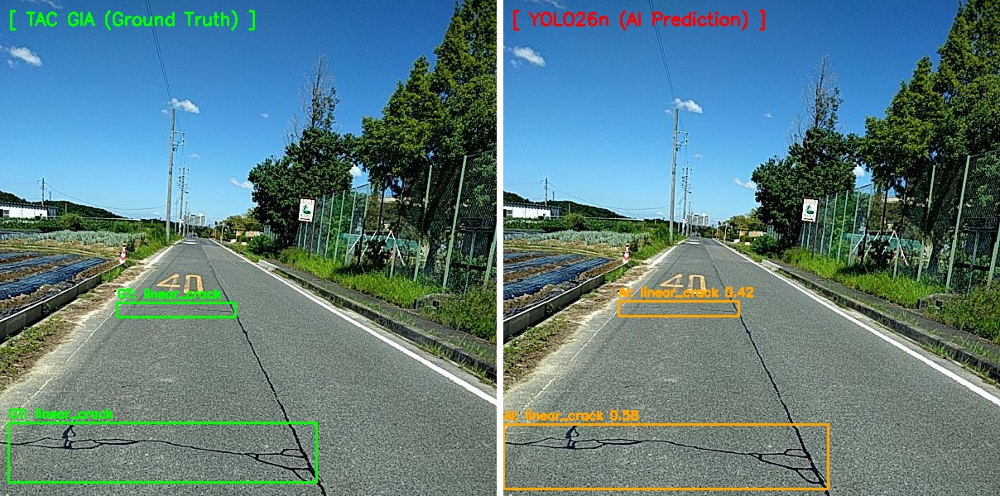

📸 ẢNH 32/50: India_006325.jpg


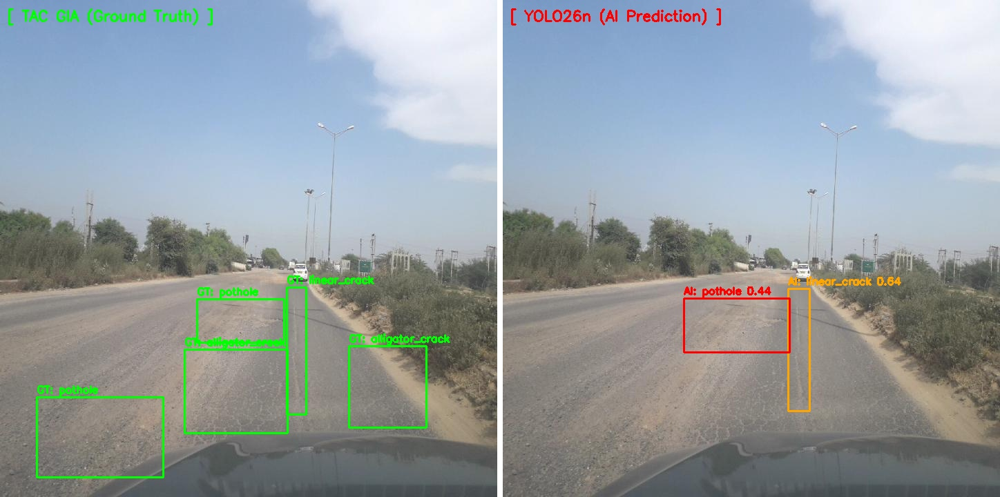

📸 ẢNH 33/50: China_MotorBike_000124.jpg


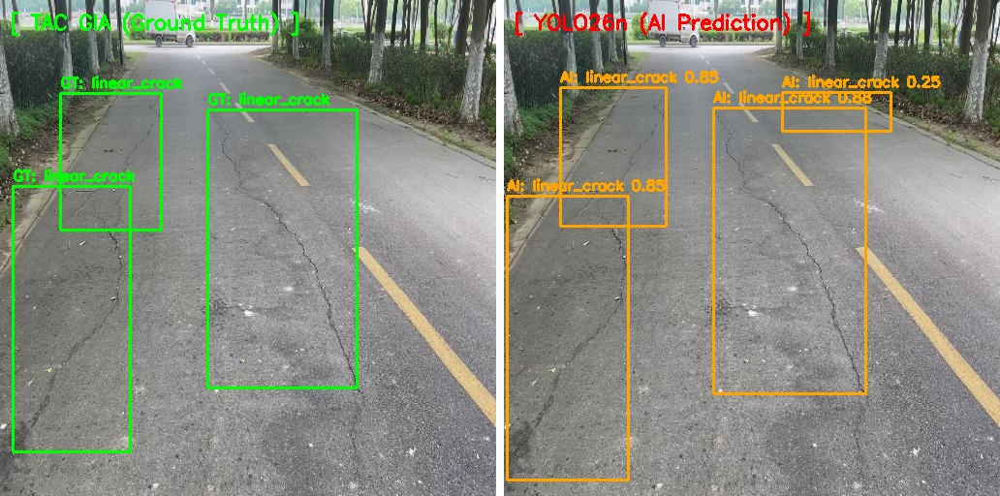

📸 ẢNH 34/50: India_002810.jpg


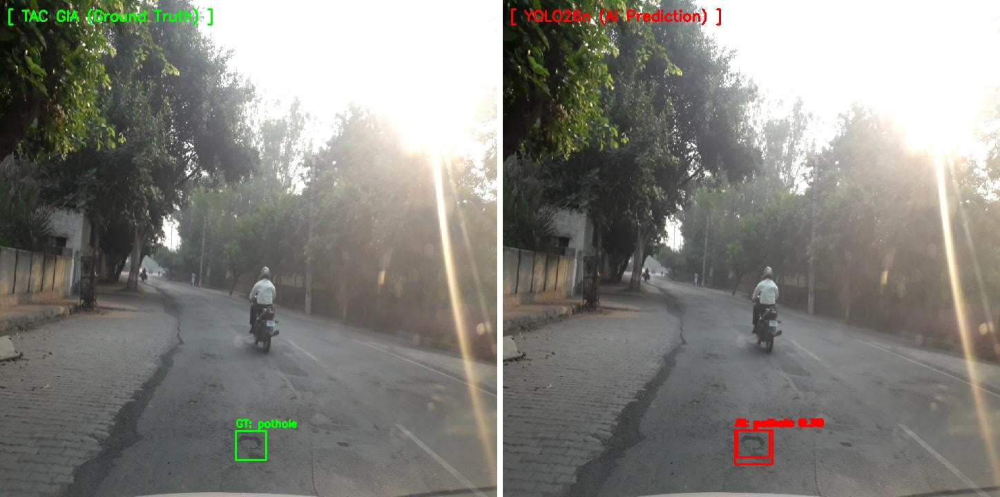

📸 ẢNH 35/50: Japan_004396.jpg


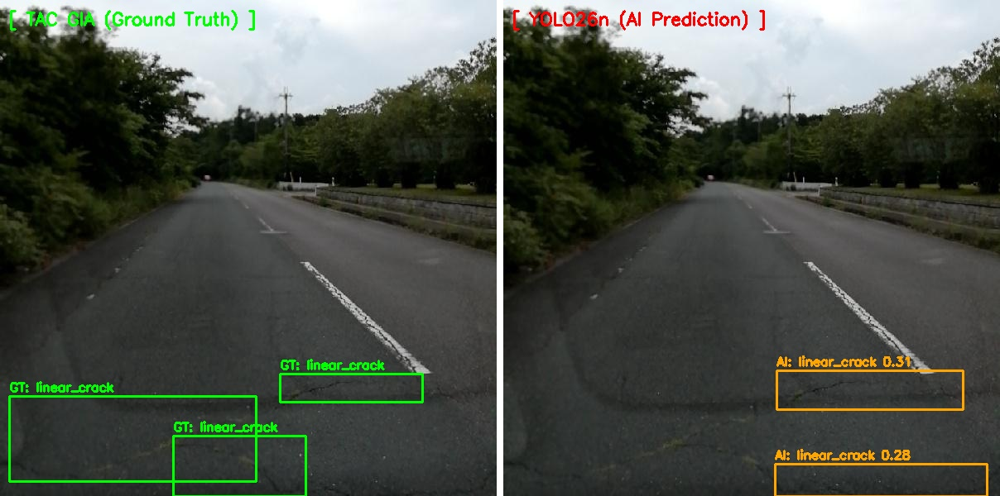

📸 ẢNH 36/50: India_000895.jpg


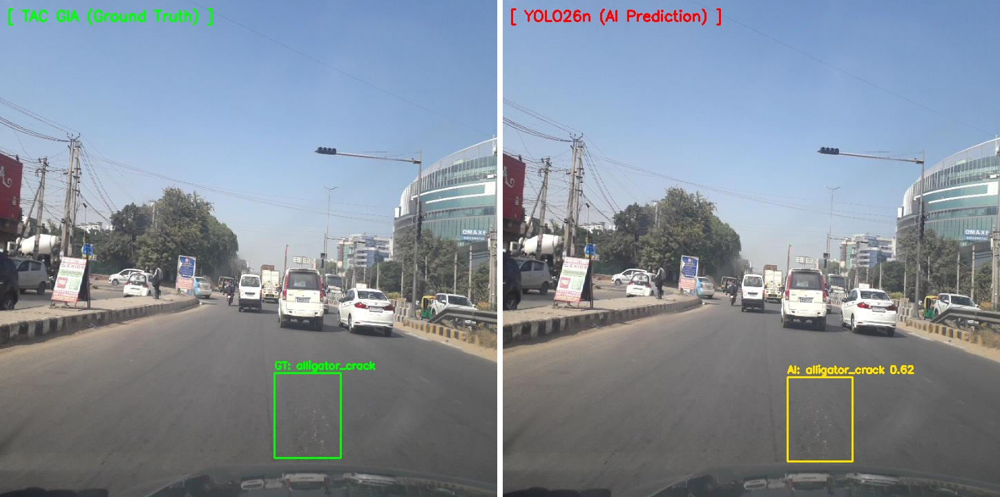

📸 ẢNH 37/50: Japan_007325.jpg


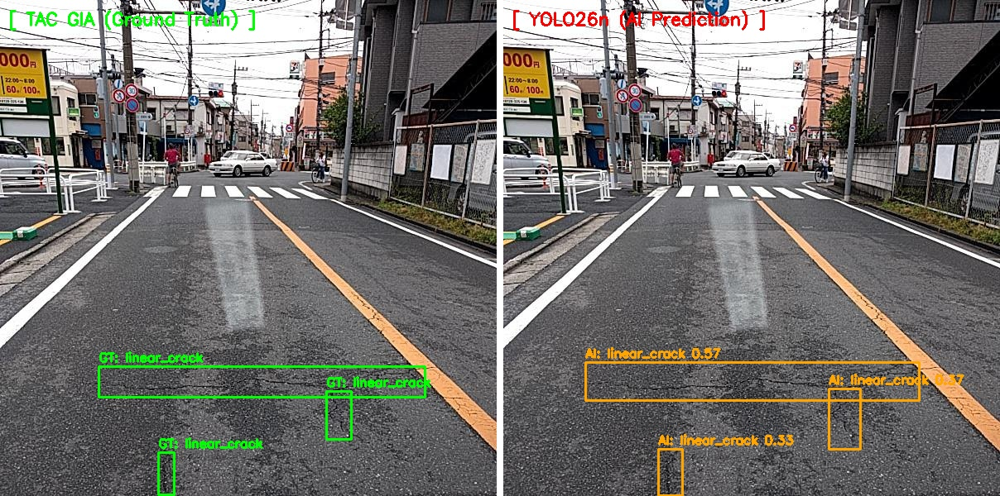

📸 ẢNH 38/50: Japan_006302.jpg


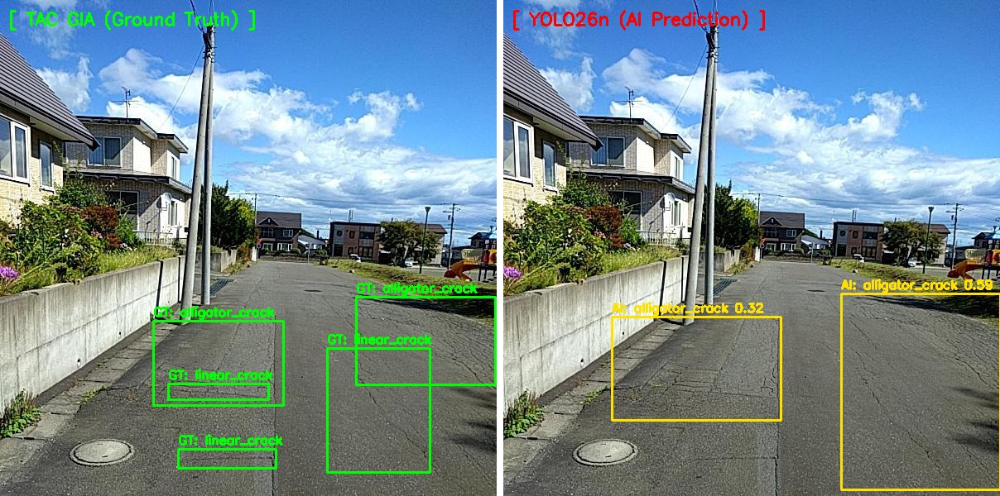

📸 ẢNH 39/50: Japan_007303.jpg


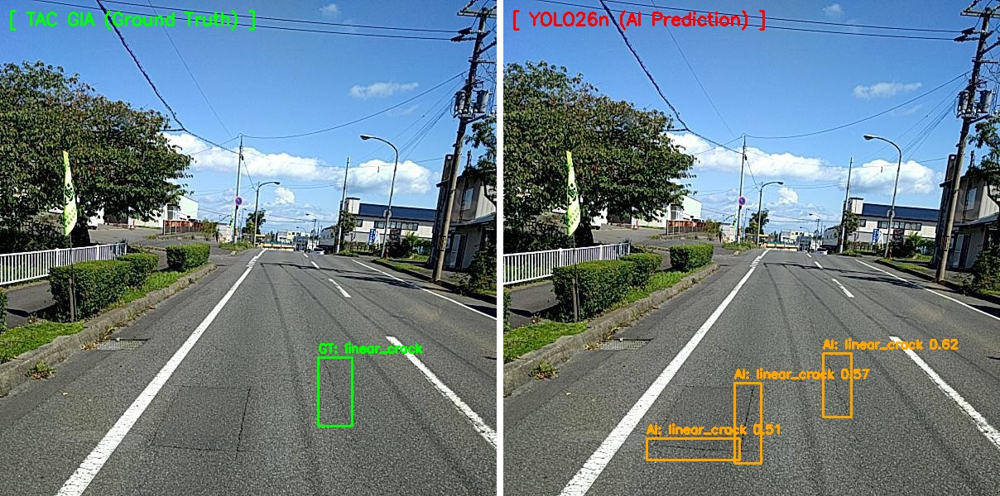

📸 ẢNH 40/50: China_Drone_001122.jpg


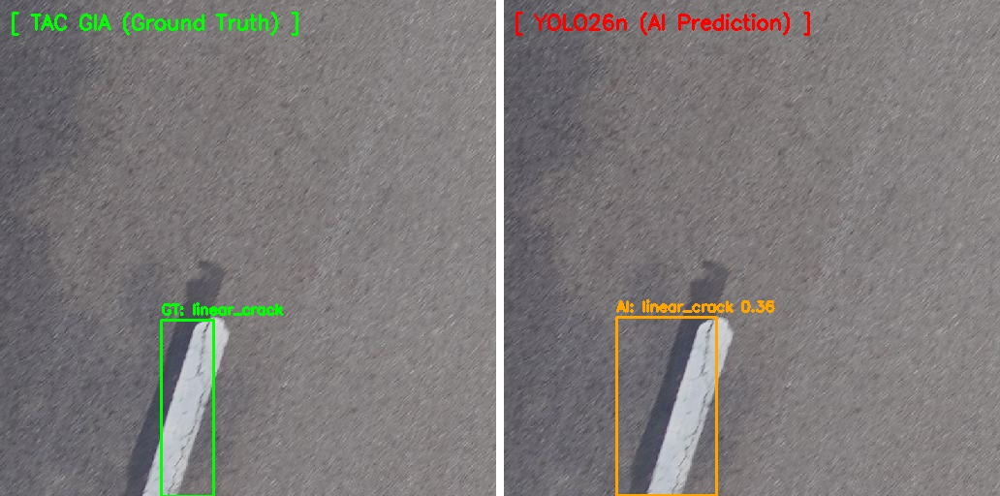

📸 ẢNH 41/50: China_MotorBike_001895.jpg


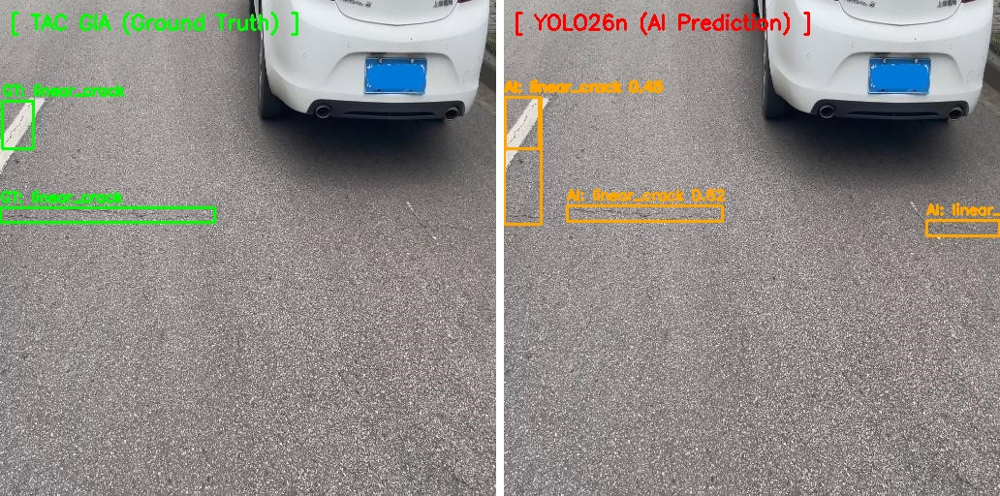

📸 ẢNH 42/50: India_005547.jpg


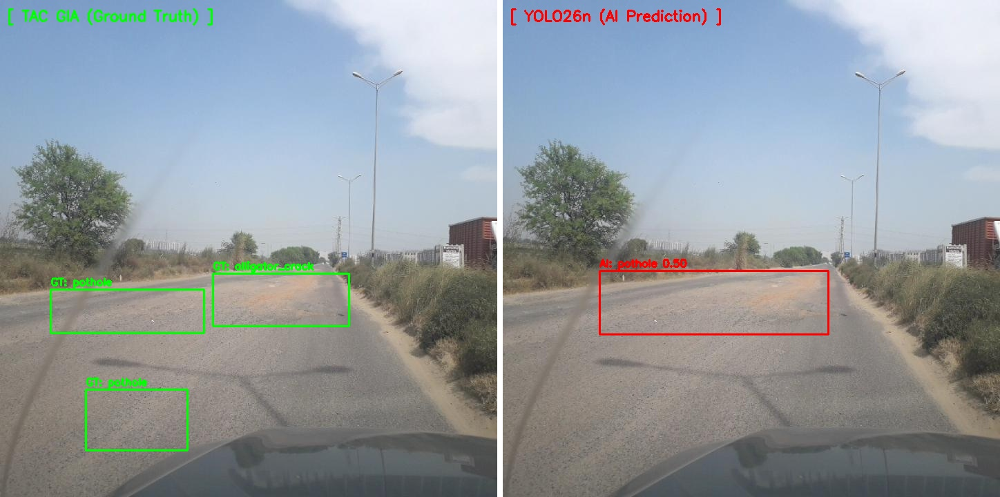

📸 ẢNH 43/50: China_Drone_000512.jpg


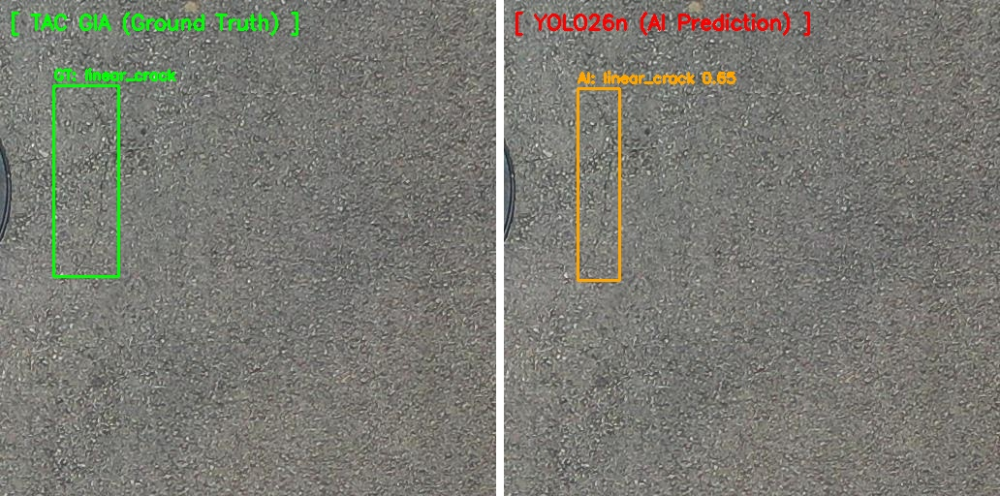

📸 ẢNH 44/50: Japan_005502.jpg


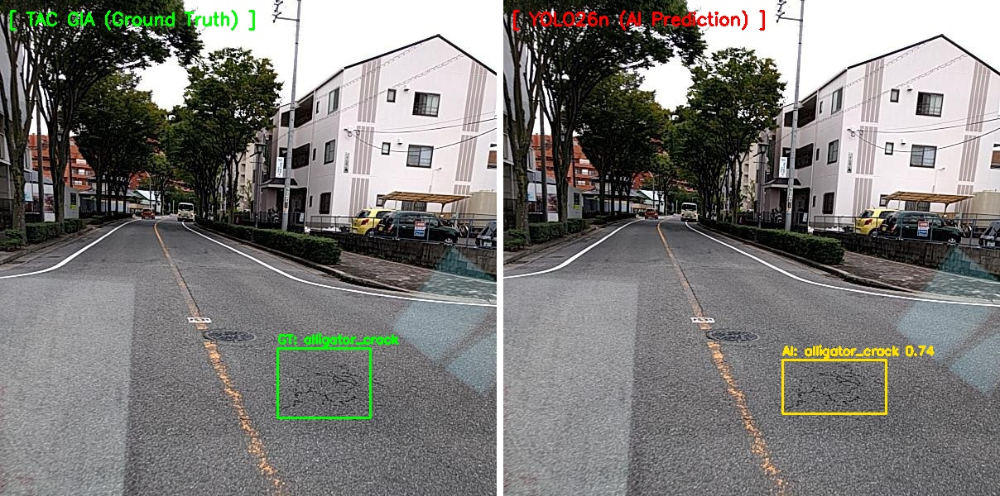

📸 ẢNH 45/50: China_Drone_000196.jpg


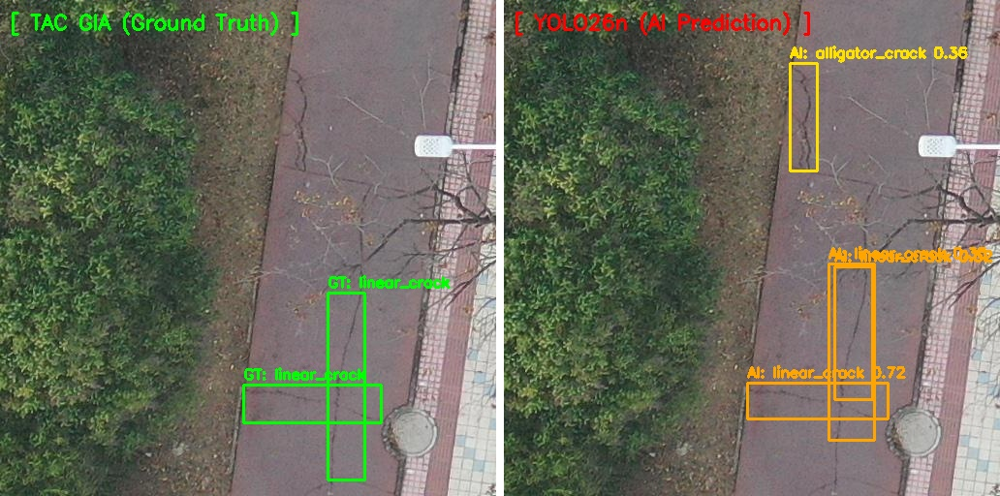

📸 ẢNH 46/50: Japan_011220.jpg


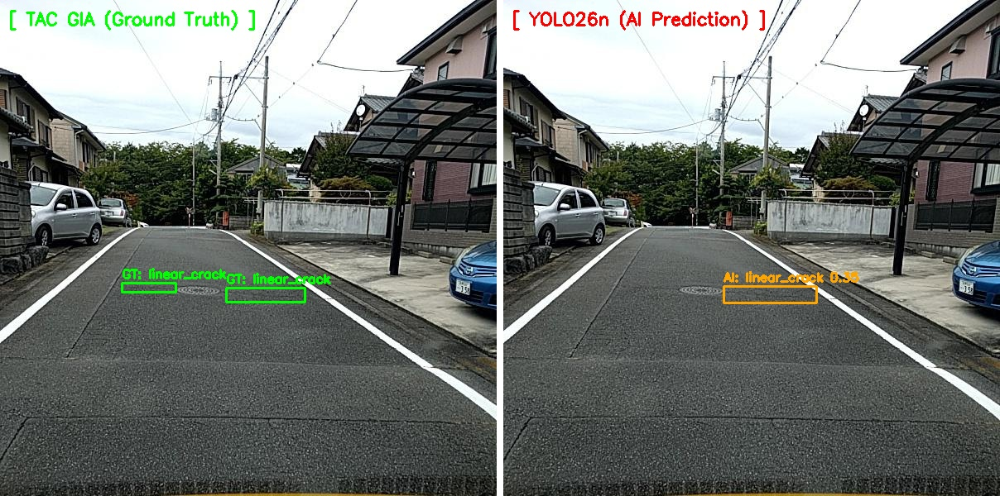

📸 ẢNH 47/50: China_Drone_000501.jpg


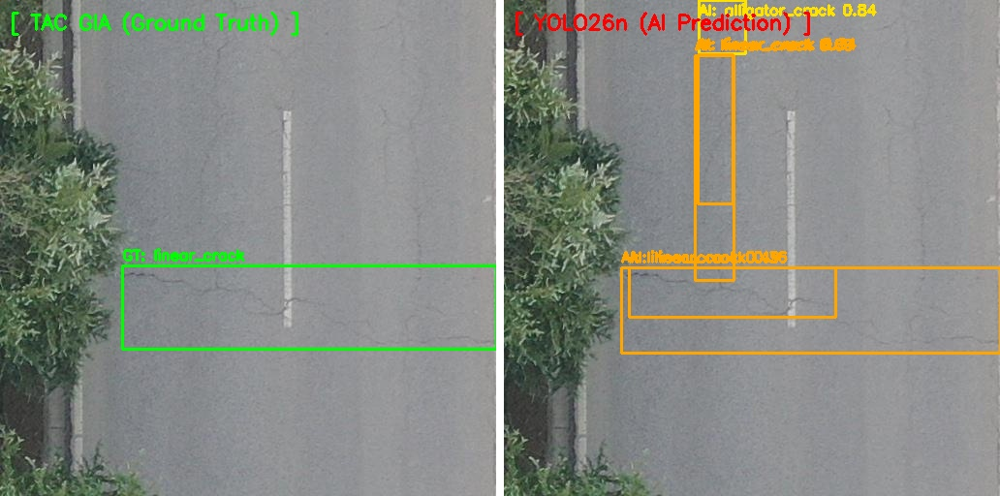

📸 ẢNH 48/50: Japan_010823.jpg


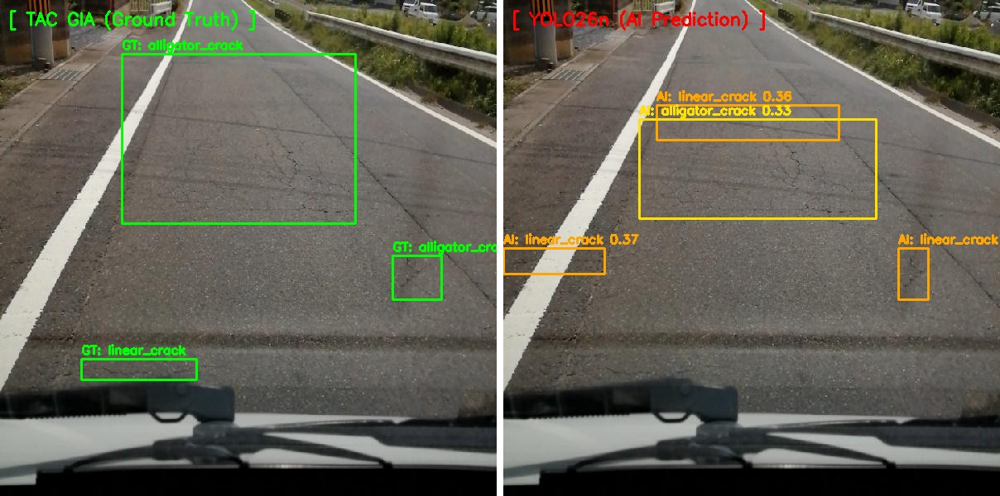

📸 ẢNH 49/50: Japan_012200.jpg


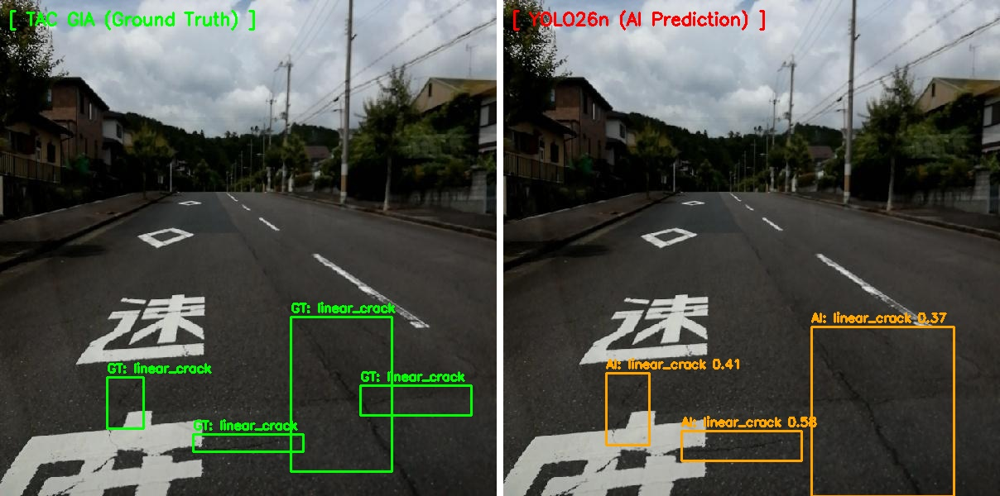

📸 ẢNH 50/50: India_004070.jpg


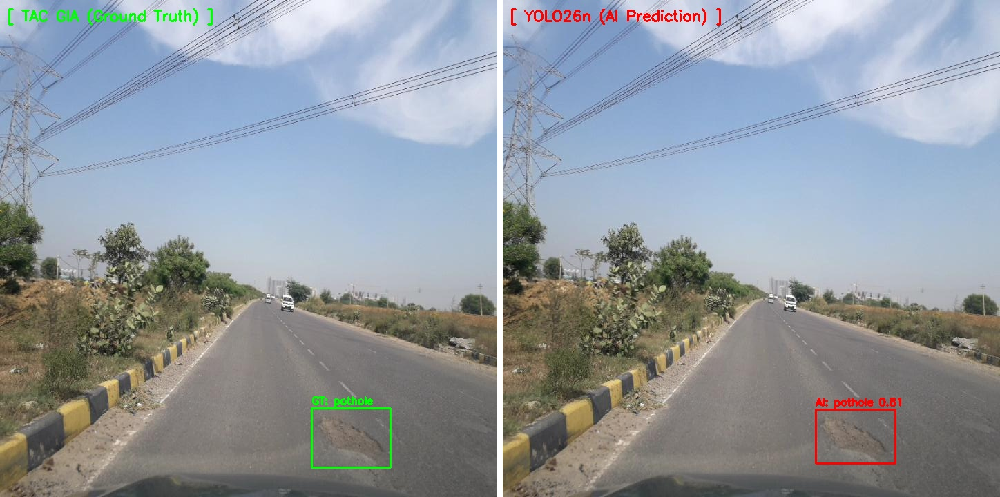


Đã nén thành file: /kaggle/working/compare_50_images.zip
Link để tải file zip:


/kaggle/working/compare_50_images.zip

In [12]:
import os
import cv2
import random
import shutil
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from IPython.display import Image, display, FileLink

# 1. Cấu hình & Tự động tìm mô hình 
VAL_IMG_DIR = Path("/kaggle/working/dataset_3class/val/images")
VAL_LBL_DIR = Path("/kaggle/working/dataset_3class/val/labels")

pt_candidates = [
    p for p in [
        Path("/kaggle/working/yolo26n_rdd_3class_best.pt"),
        Path("/kaggle/working/civiceye_training/yolo26n_rdd2022/weights/best.pt")
    ] if p.exists()
]
if not pt_candidates:
    pt_candidates = list(Path("/kaggle/working").rglob("*best.pt"))

MODEL_PATH = str(pt_candidates[0])

CLASS_NAMES = {0: "pothole", 1: "linear_crack", 2: "alligator_crack"}
COLOR_GT = (0, 255, 0) # Xanh lá
COLORS_PRED = {
    "pothole": (0, 0, 255),           # Đỏ
    "linear_crack": (0, 165, 255),    # Cam
    "alligator_crack": (0, 225, 255), # Vàng
}

# 2. Hàm vẽ nhãn (Ground Truth & AI Prediction)
def draw_ground_truth(img, label_path):
    h, w = img.shape[:2]
    if not label_path.exists():
        return img
    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5: 
                continue
            cls_id = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:5])
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            label = CLASS_NAMES.get(cls_id, str(cls_id))
            cv2.rectangle(img, (x1, y1), (x2, y2), COLOR_GT, 2)
            cv2.putText(img, f"GT: {label}", (x1, max(15, y1 - 6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, COLOR_GT, 2)
    return img

def draw_predictions(img, model, conf=0.25):
    results = model.predict(img, conf=conf, verbose=False)[0]
    if results.boxes is not None:
        for box in results.boxes:
            cls_id = int(box.cls[0])
            conf_val = float(box.conf[0])
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            label = CLASS_NAMES.get(cls_id, str(cls_id))
            color = COLORS_PRED.get(label, (0, 0, 255))
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, f"AI: {label} {conf_val:.2f}", (x1, max(15, y1 - 6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return img

# 3. Lấy 50 ảnh có nhãn trong tập Val & Ghép ảnh song song
model = YOLO(MODEL_PATH)
val_images = [p for p in VAL_IMG_DIR.glob("*.*") if p.suffix.lower() in [".jpg", ".jpeg", ".png"] and (VAL_LBL_DIR / f"{p.stem}.txt").exists()]

NUM_SAMPLES = 50
random.seed(42)
sampled_images = random.sample(val_images, min(NUM_SAMPLES, len(val_images)))

out_dir = Path("/kaggle/working/comparison_50_results")
out_dir.mkdir(parents=True, exist_ok=True)


for idx, img_p in enumerate(sampled_images, start=1):
    orig = cv2.imread(str(img_p))
    if orig is None: 
        continue
    h, w = orig.shape[:2]
    
    # Bên Trái: Nhãn Tác giả
    lbl_p = VAL_LBL_DIR / f"{img_p.stem}.txt"
    left_img = draw_ground_truth(orig.copy(), lbl_p)
    cv2.putText(left_img, "[ TAC GIA (Ground Truth) ]", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    
    # Bên Phải: AI Dự đoán
    right_img = draw_predictions(orig.copy(), model, conf=0.25)
    cv2.putText(right_img, "[ YOLO26n (AI Prediction) ]", (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    
    # Ghép đôi song song
    divider = np.full((h, 8, 3), 255, dtype=np.uint8)
    combined = np.hstack([left_img, divider, right_img])
    
    out_file = out_dir / f"compare_{idx:02d}_{img_p.name}"
    cv2.imwrite(str(out_file), combined)
    
    # Hiển thị trước 50 ảnh mẫu ngay trên màn hình
    if idx <= 50:
        print(f"📸 ẢNH {idx}/50: {img_p.name}")
        display(Image(filename=str(out_file), width=900))

# 4. Nén toàn bộ 50 ảnh thành file zip
zip_path = shutil.make_archive("/kaggle/working/compare_50_images", "zip", out_dir)
print("\n" + "=" * 65)
print(f"Đã nén thành file: {zip_path}")
print("Link để tải file zip:")
display(FileLink("compare_50_images.zip"))
print("=" * 65)
